# 03 — Exploratory Data Analysis (EDA)

## Project: Evaluating Low-Cost PM2.5 Sensors: Calibration Accuracy, Generalization, and Reliability

### 1. Purpose of This Notebook

This notebook performs exploratory data analysis (EDA) on the two datasets used in this project to understand their distributions, relationships, temporal patterns, regional characteristics, and potential data-quality issues.

The previous notebooks established the foundation for this analysis:

- `01_data_profile.ipynb` examined the structure, completeness, consistency, and quality of the source datasets.
- `02_analytical_decisions.ipynb` documented the initial analytical framework, supporting evidence, methodological principles, and decisions that will guide subsequent analysis.

The purpose of this notebook is to examine the actual data patterns before finalizing data-dependent preprocessing choices, calibration model specifications, and evaluation strategies.

EDA will be conducted systematically, with each dataset examined separately before considering relevant comparisons between them.

### 2. Research Question

**How much does calibration improve agreement between low-cost PurpleAir sensors and reference monitors, and does the improvement hold under wildfire-smoke conditions?**

The exploratory analysis will support this question by examining the characteristics of the raw sensor measurements, reference measurements, environmental variables, and available correction approaches.

### 3. Datasets

This project uses two datasets with different temporal resolutions and analytical structures.

#### Dataset A — 24-Hour Collocation

**File:** `Full24hrdataset.csv`

Dataset A contains daily PurpleAir PM2.5 measurements paired with Federal Equivalent Method (FEM) and Federal Reference Method (FRM) measurements.

The dataset includes:

- PurpleAir site identifiers, dates, and geographic regions.
- Reference PM2.5 measurements (`PM25FM`).
- Reference measurement categories (`FEMorFRM`).
- Raw PurpleAir PM2.5 measurements (`PM25cf1` and `PM25cfatm`).
- Meteorological variables, including relative humidity (`RH`), temperature (`TempC`), and dew point (`Dewpoint`).
- Previously corrected PurpleAir measurements (`PM25PAlinearcor` and `PM25PARHcor`).

Dataset A will primarily support the investigation of daily calibration relationships, reference-monitor agreement, and differences across sites and regions.

#### Dataset B — Hourly Wildfire-SMoke Observations

**File:** `Finaldataset_correcteddatasetwholding_10_26_22.csv`

Dataset B contains hourly PurpleAir PM2.5 measurements, reference-monitor measurements, relative humidity, and previously published adjusted measurements under different correction and withholding configurations.

The dataset includes:

- City and sensor identifiers.
- Date and time-related information.
- Raw PurpleAir PM2.5 measurements (`PA`).
- Reference PM2.5 measurements (`ref`).
- Relative humidity (`RH`).
- Adjusted PM2.5 measurements (`adj`).
- Six adjustment approaches (A–F).
- Two withholding approaches: LOBD and LOSO.

The adjustment approaches represent different previously developed correction methods. The withholding approaches represent different data-holding strategies used in the source dataset.

Dataset B will support the investigation of hourly measurement behavior and calibration performance under the wildfire-smoke conditions represented in the dataset.

Repeated adjustment and withholding configurations will be recognized as versions of the same underlying observations rather than automatically treated as independent measurements.

### 4. Main Objectives of EDA

The exploratory analysis will address the following objectives:

1. **Understand data distributions:** Examine the distributions, ranges, central tendencies, and variability of PM2.5 measurements and environmental variables.
2. **Investigate relationships:** Explore relationships between raw PurpleAir measurements, reference measurements, and meteorological variables.
3. **Examine measurement agreement:** Investigate differences between PurpleAir and reference measurements, including potential systematic bias and concentration-dependent errors.
4. **Identify unusual observations:** Examine extreme values, nonpositive measurements, missingness, and other potentially influential observations without automatically excluding them.
5. **Investigate temporal patterns:** Examine daily and hourly variation, seasonal patterns, and changes over time where supported by the available data.
6. **Investigate regional and site-level differences:** Examine how measurement behavior varies across PurpleAir sites, regions, and cities.
7. **Explore meteorological effects:** Investigate the relationships between relative humidity, temperature, dew point, and PM2.5 measurement errors.
8. **Examine wildfire-smoke conditions:** Investigate elevated PM2.5 concentrations and the behavior of raw and adjusted measurements in Dataset B.
9. **Assess data suitability for modeling:** Identify patterns and limitations that may affect feature selection, preprocessing, data partitioning, and evaluation.

### 5. EDA Workflow

The analysis will follow this sequence:

#### Part 1 — Dataset A: 24-Hour Collocation

1. Load the existing Dataset A without modifying the original source data.
2. Review its dimensions, variables, data types, and basic structure.
3. Examine the distributions of reference and raw PurpleAir PM2.5 measurements.
4. Investigate FEM and FRM measurement distributions and differences.
5. Examine relationships between raw PurpleAir measurements and reference PM2.5.
6. Explore measurement errors and their relationship with PM2.5 concentration.
7. Investigate relative humidity, temperature, and dew point relationships.
8. Examine temporal, regional, and site-level patterns.
9. Revisit missing values, nonpositive measurements, and unusual observations where relevant.

#### Part 2 — Dataset B: Hourly Wildfire-SMoke Observations

1. Load the Dataset B source data and examine its structure.
2. Investigate city, sensor, date, and time distributions.
3. Examine raw PurpleAir and reference PM2.5 distributions.
4. Investigate relative humidity and its relationship with measurement differences.
5. Examine the six adjustment approaches (A–F).
6. Examine the two withholding approaches (LOBD and LOSO).
7. Investigate performance patterns across PM2.5 concentration ranges and wildfire-smoke conditions.
8. Examine repeated configuration records and the underlying observation structure.
9. Identify limitations that may affect subsequent evaluation.

#### Part 3 — Combined Interpretation

After exploring the datasets separately:

1. Summarize the main findings from Dataset A and Dataset B.
2. Identify similarities and differences in measurement behavior.
3. Assess which comparisons are analytically meaningful given their different temporal resolutions and sampling structures.
4. Identify unresolved methodological questions.
5. Update provisional analytical decisions where the evidence supports doing so.

### 6. Analytical Principles

The following principles will guide EDA:

- Preserve original source data.
- Do not automatically remove extreme or unusual observations.
- Do not automatically impute missing values.
- Distinguish data-quality issues from genuine measurement variation.
- Keep repeated observations and correction configurations identifiable.
- Use appropriate comparisons for each dataset's temporal resolution and structure.
- Avoid treating repeated or dependent observations as independent evidence.
- Document findings and limitations before changing analytical decisions.
- Do not train or select final calibration models in this notebook.

### 7. Expected Outcome

By the end of this notebook, the project should have:

- A clear understanding of the distributions and relationships within both datasets.
- An assessment of potential measurement bias and concentration-dependent errors.
- An understanding of environmental, temporal, regional, and site-level patterns.
- An assessment of unusual observations and missing-data implications.
- A documented understanding of Dataset B's adjustment and withholding configurations.
- Evidence to refine provisional analytical decisions.
- A justified foundation for the subsequent calibration and evaluation stages.

### 8. Next Stage

The findings from this notebook will guide:

`04_calibration_and_evaluation.ipynb`

This subsequent notebook will focus on developing calibration models, preventing data leakage, evaluating held-out performance, and investigating whether calibration improvements generalize under wildfire-smoke conditions.

---

**Note:** EDA is an investigative stage. Findings will be documented before changing data, excluding observations, or finalizing modeling choices. All analytical transformations and derived variables will be created separately from the original source datasets.

In [178]:
from pathlib import Path
import pandas as pd

# Find the project root from the notebook's current directory.
current_dir = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path
        for path in (current_dir, *current_dir.parents)
        if (path / "data" / "raw").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root. Open this notebook "
        "from inside the low-cost-pm25-calibration repository."
    )

RAW_DIR = PROJECT_ROOT / "data" / "raw"

COLLOCATION_DIR = RAW_DIR / "24hr_collocation"
SMOKE_DIR = RAW_DIR / "hourly_smoke"

COLLOCATION_FILE = COLLOCATION_DIR / "Full24hrdataset.csv"
SMOKE_FILE = (
    SMOKE_DIR
    / "Finaldataset_correcteddatasetwholding_10_26_22.csv"
)

# Verify both source files.
required_files = {
    "24-hour collocation dataset": COLLOCATION_FILE,
    "Hourly wildfire-smoke dataset": SMOKE_FILE,
}

for dataset_name, file_path in required_files.items():
    if not file_path.is_file():
        raise FileNotFoundError(
            f"{dataset_name} is missing: {file_path}"
        )

    print(
        f"{dataset_name}: available "
        f"({file_path.stat().st_size:,} bytes)"
    )

# Load both datasets without modifying the source files.
df_24hr = pd.read_csv(COLLOCATION_FILE, low_memory=False)

df_smoke = pd.read_csv(SMOKE_FILE, low_memory=False)

# Display dataset dimensions.
print("\nDataset A — 24-hour Collocation")
print(f"Rows: {len(df_24hr):,}")
print(f"Columns: {df_24hr.shape[1]:,}")

print("\nDataset B — Hourly Wildfire Smoke")
print(f"Rows: {len(df_smoke):,}")
print(f"Columns: {df_smoke.shape[1]:,}")

24-hour collocation dataset: available (6,420,524 bytes)
Hourly wildfire-smoke dataset: available (261,969,901 bytes)

Dataset A — 24-hour Collocation
Rows: 12,430
Columns: 31

Dataset B — Hourly Wildfire Smoke
Rows: 1,513,776
Columns: 13


## Part 1 — Exploratory Data Analysis: Dataset A (24-Hour Collocation)

Dataset A contains daily PurpleAir PM2.5 measurements paired with FEM/FRM reference-monitor measurements.

The purpose of this section is to explore the distributions, relationships, measurement differences, environmental influences, and regional and temporal patterns in the dataset.

The analysis will build on the data profiling already completed in `01_data_profile.ipynb`. Previously established findings will be reused rather than recalculated unnecessarily.


### PM2.5 Measurement Distributions

The first stage of EDA examines the distributions of reference-monitor PM2.5 measurements and the two raw PurpleAir PM2.5 measurements.

The objective is to understand their concentration ranges, variability, skewness, and potential extreme observations.

The following variables will be examined:

- `PM25FM`: Reference-monitor PM2.5 concentration.
- `PM25cf1`: Raw PurpleAir CF=1 PM2.5 concentration.
- `PM25cfatm`: Raw PurpleAir CF=ATM PM2.5 concentration.

No observations will be removed or modified during this initial examination.

In [179]:

# Locate the project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

FIGURES_DIR = project_root / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Figures folder:", FIGURES_DIR.resolve())
print("Folder exists:", FIGURES_DIR.exists())

Figures folder: reports/figures
Folder exists: True


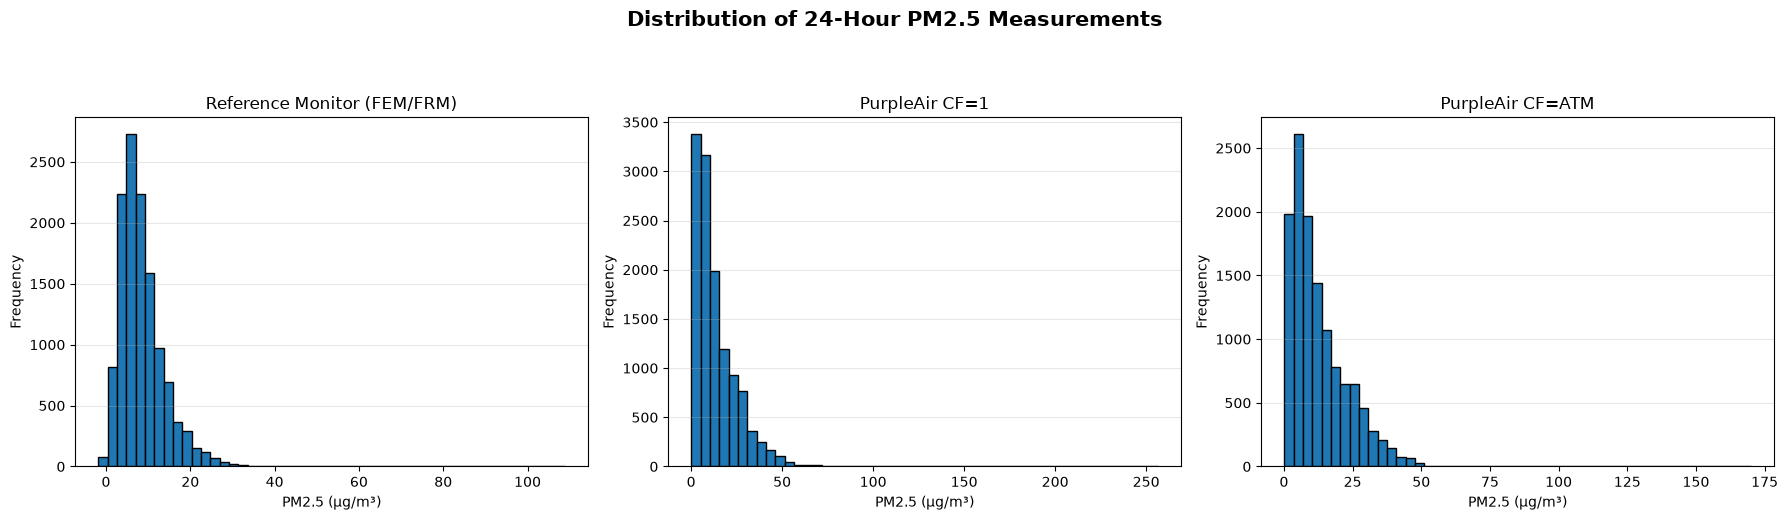

Figure saved to: reports/figures/dataset_a_pm25_distributions.png


In [180]:
import matplotlib.pyplot as plt

# Variables to examine
pm25_variables = {
    "PM25FM": "Reference Monitor (FEM/FRM)",
    "PM25cf1": "PurpleAir CF=1",
    "PM25cfatm": "PurpleAir CF=ATM"
}

# Plot distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (column, title) in zip(axes, pm25_variables.items()):
    values = df_24hr[column].dropna()

    ax.hist(values, bins=50, edgecolor="black")
    ax.set_title(title)
    ax.set_xlabel("PM2.5 (µg/m³)")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Distribution of 24-Hour PM2.5 Measurements",
    fontsize=15,
    fontweight="bold",
    y=1.03
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

figure_path = FIGURES_DIR / "dataset_a_pm25_distributions.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", figure_path.resolve())

**Figure.** Distributions of 24-hour reference monitor PM2.5 (PM25FM), PurpleAir CF=1 (PM25cf1), and PurpleAir CF=ATM (PM25cfatm) measurements in Dataset A. All three distributions are right-skewed. The PurpleAir measurements show longer upper tails than the reference measurements, indicating higher values in their upper ranges.

In [181]:
# Calculate descriptive statistics for the three PM2.5 variables.
pm25_columns = ["PM25FM", "PM25cf1", "PM25cfatm"]

distribution_summary = df_24hr[pm25_columns].describe().T

distribution_summary["median"] = df_24hr[pm25_columns].median()
distribution_summary["skewness"] = df_24hr[pm25_columns].skew()
distribution_summary["nonpositive_count"] = (
    df_24hr[pm25_columns].le(0).sum()
)

distribution_summary.round(3)

,count,mean,std,min,25%,50%,75%,max,median,skewness,nonpositive_count
PM25FM,12430.0,8.517,5.386,-1.778,4.834,7.349,10.917,108.800,7.349,2.020,44
PM25cf1,12430.0,13.363,11.659,0.182,4.973,9.707,18.712,256.310,9.707,2.367,0
PM25cfatm,12430.0,12.776,10.241,0.182,4.955,9.621,18.289,169.908,9.621,1.491,0


### Findings — PM2.5 Measurement Distributions

The initial distribution analysis revealed the following:

1. All three PM2.5 variables exhibit right-skewed distributions, with their means exceeding their medians.
2. The reference measurement (`PM25FM`) has a mean of 8.517 µg/m³ and a median of 7.349 µg/m³.
3. The raw PurpleAir CF=1 measurement (`PM25cf1`) has a mean of 13.363 µg/m³, while CF=ATM (`PM25cfatm`) has a mean of 12.776 µg/m³.
4. CF=1 exhibits a more pronounced upper tail, with a maximum of 256.310 µg/m³ compared with 169.908 µg/m³ for CF=ATM.
5. The reference variable contains 44 nonpositive observations, consistent with the findings documented in Decision 2.

**Initial interpretation:**

The distributions suggest potential differences between raw PurpleAir and reference measurements, particularly at higher concentrations. However, distribution summaries alone cannot establish measurement agreement or systematic bias. These relationships will be investigated using paired observations in subsequent analysis.

No observations were removed or modified during this analysis.

In [182]:
# Examine upper-tail concentration levels.
upper_tail_summary = (
    df_24hr[["PM25FM", "PM25cf1", "PM25cfatm"]]
    .quantile([0.90, 0.95, 0.99, 0.995])
    .T
)

upper_tail_summary.columns = [
    "90th_percentile",
    "95th_percentile",
    "99th_percentile",
    "99.5th_percentile"
]

upper_tail_summary.round(3)

,90th_percentile,95th_percentile,99th_percentile,99.5th_percentile
PM25FM,15.300,18.790,26.032,28.629
PM25cf1,28.875,36.222,50.028,57.750
PM25cfatm,27.561,33.266,43.759,47.285


### Findings — Upper-Tail PM2.5 Concentrations

The upper-tail analysis shows increasingly different concentration distributions among the reference and raw PurpleAir measurements.

Key observations:

1. At the 90th percentile, the reference concentration is 15.300 µg/m³, compared with 28.875 µg/m³ for CF=1 and 27.561 µg/m³ for CF=ATM.
2. At the 95th percentile, CF=1 reaches 36.222 µg/m³, compared with 18.790 µg/m³ for the reference.
3. At the 99th percentile, CF=1 reaches 50.028 µg/m³, while CF=ATM reaches 43.759 µg/m³ and the reference reaches 26.032 µg/m³.
4. The difference between the two raw PurpleAir measurements becomes more pronounced toward the upper end of their distributions.

**Initial interpretation:**

The raw PurpleAir and reference measurements have substantially different upper-tail distributions. CF=1 also exhibits higher upper percentiles than CF=ATM.

However, these percentile comparisons are based on marginal distributions and do not establish paired measurement bias. The relationship between corresponding PurpleAir and reference observations will be examined next.

No outlier thresholds or exclusions have been established from these results.

### Paired Measurement Relationships

The previous analyses examined the distributions of reference and raw PurpleAir PM2.5 measurements independently.

This section examines their paired relationships to investigate how closely the raw PurpleAir measurements agree with corresponding reference measurements.

Two comparisons will be examined:

- `PM25FM` against `PM25cf1`.
- `PM25FM` against `PM25cfatm`.

A 1:1 reference line will be included to represent perfect agreement between the PurpleAir and reference measurements.

The analysis will help identify systematic differences, concentration-dependent patterns, and observations that deviate substantially from the reference.

Repeated reference observations sharing the same PurpleAir site-date measurement will be retained and recognized when interpreting the plots.

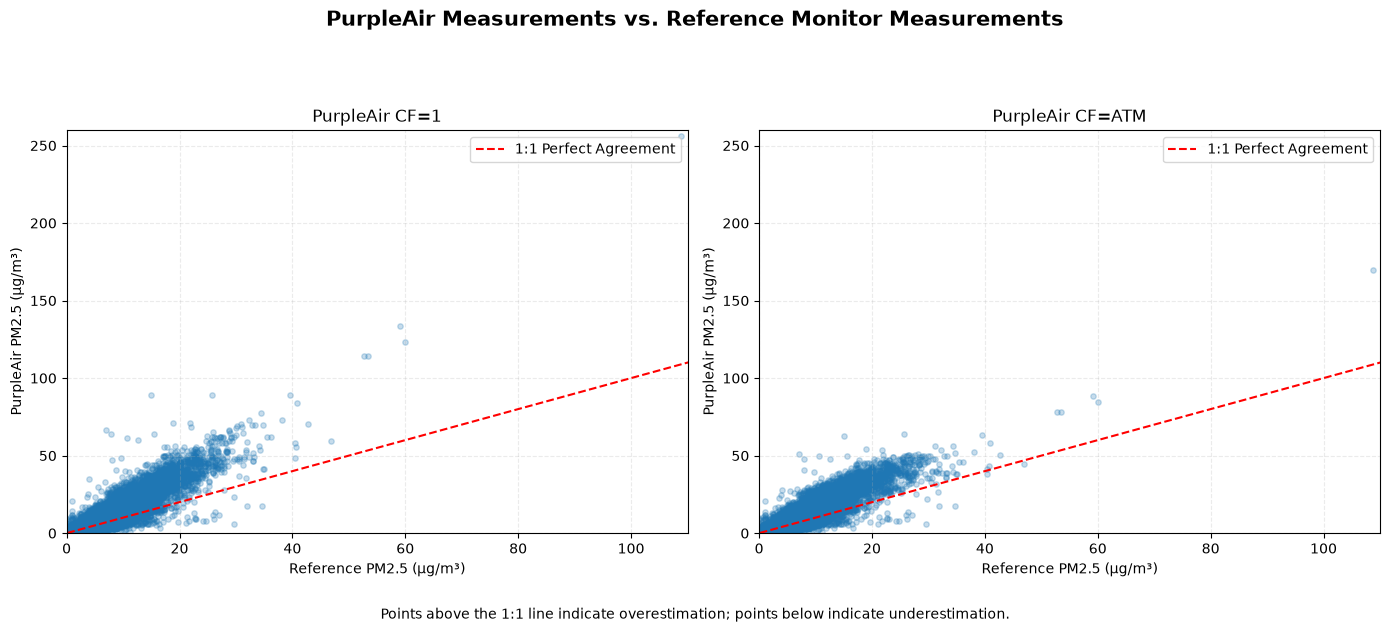

Figure saved to: reports/figures/dataset_a_purpleair_vs_reference.png


In [183]:
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

comparisons = [
    ("PM25cf1", "PurpleAir CF=1"),
    ("PM25cfatm", "PurpleAir CF=ATM")
]

# Common plotting range
plot_min = min(
    df_24hr["PM25FM"].min(),
    df_24hr["PM25cf1"].min(),
    df_24hr["PM25cfatm"].min()
)

plot_max = max(
    df_24hr["PM25FM"].max(),
    df_24hr["PM25cf1"].max(),
    df_24hr["PM25cfatm"].max()
)

for ax, (column, title) in zip(axes, comparisons):

    ax.scatter(
        df_24hr["PM25FM"],
        df_24hr[column],
        alpha=0.25,
        s=15
    )

    ax.plot(
        [plot_min, plot_max],
        [plot_min, plot_max],
        linestyle="--",
        color="red",
        label="1:1 Perfect Agreement"
    )

    ax.set_title(title)
    ax.set_xlabel("Reference PM2.5 (µg/m³)")
    ax.set_ylabel("PurpleAir PM2.5 (µg/m³)")
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle(
    "PurpleAir Measurements vs. Reference Monitor Measurements",
    fontsize=15,
    fontweight="bold",
    y=1.03
)

for ax in axes:
    ax.set_xlim(0, 110)
    ax.set_ylim(0, 260)
    ax.grid(True, linestyle="--", alpha=0.25)

fig.text(
    0.5,
    0.015,
    "Points above the 1:1 line indicate overestimation; "
    "points below indicate underestimation.",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.06, 1, 0.95])

figure_path = FIGURES_DIR / "dataset_a_purpleair_vs_reference.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", figure_path.resolve())

**Figure.** Scatterplots comparing PurpleAir CF=1 and CF=ATM measurements with reference monitor PM2.5 measurements in Dataset A. The red dashed line represents perfect agreement. Points above the line indicate PurpleAir overestimation, while points below indicate underestimation. The plots show substantial dispersion around the reference line, particularly at higher concentrations.

## Findings — Paired Measurement Relationships

The scatterplots comparing raw PurpleAir measurements with reference PM2.5 measurements reveal the following:

- Most observations are concentrated at relatively low PM2.5 concentrations.
- A substantial proportion of observations lie above the 1:1 agreement line, suggesting that raw PurpleAir measurements are frequently higher than corresponding reference measurements.
- CF=1 exhibits a wider visible spread around the agreement line, particularly at higher concentrations.
- CF=ATM also shows deviations from the agreement line, although its visible spread appears narrower.
- Several observations occur at unusually high concentrations and require further investigation.

**Initial interpretation:**

The scatterplots suggest that raw PurpleAir measurements do not consistently agree with reference-monitor measurements. The differences may also vary with concentration.

These visual observations will be quantified through paired measurement differences and error summaries in the next analysis.

No observations have been removed or modified.

In [184]:
# Calculate paired measurement differences.
paired_differences = pd.DataFrame({
    "CF1_difference": df_24hr["PM25cf1"] - df_24hr["PM25FM"],
    "CFATM_difference": df_24hr["PM25cfatm"] - df_24hr["PM25FM"]
})

# Summarize the differences.
difference_summary = paired_differences.describe().T

difference_summary["median"] = paired_differences.median()
difference_summary["mean_bias"] = paired_differences.mean()

difference_summary.round(3)

,count,mean,std,min,25%,50%,75%,max,median,mean_bias
CF1_difference,12430.0,4.845,7.355,-23.487,-0.262,2.766,8.414,147.510,2.766,4.845
CFATM_difference,12430.0,4.259,6.125,-23.487,-0.282,2.673,7.818,61.108,2.673,4.259


## Findings — Paired Measurement Differences

The paired measurement differences indicate that both raw PurpleAir measurements have positive average bias relative to the reference measurements.

Key findings:

- CF=1 has a mean difference of +4.845 µg/m³, while CF=ATM has a mean difference of +4.259 µg/m³.
- The median differences are also positive: 2.766 µg/m³ for CF=1 and 2.673 µg/m³ for CF=ATM.
- CF=ATM has lower variability in the differences, with a standard deviation of 6.125 compared with 7.355 for CF=1.
- The maximum positive difference is substantially larger for CF=1 (147.510 µg/m³) than for CF=ATM (61.108 µg/m³).
- Negative differences are also present, indicating that both raw measurements sometimes underestimate the reference.

**Initial interpretation:**

Both raw PurpleAir measurements tend to overestimate reference PM2.5 on average. CF=ATM shows slightly lower average bias and variability in this initial comparison.

However, signed differences alone cannot establish which measurement is more accurate because positive and negative errors can offset one another. Absolute and squared errors will be examined next.

No observations have been removed or modified.

In [185]:
# Calculate absolute and squared errors.
absolute_errors = paired_differences.abs()

error_summary = pd.DataFrame({
    "MAE": absolute_errors.mean(),
    "Median_absolute_error": absolute_errors.median(),
    "RMSE": np.sqrt((paired_differences ** 2).mean()),
    "Mean_bias": paired_differences.mean()
})

error_summary.round(3)

,MAE,Median_absolute_error,RMSE,Mean_bias
CF1_difference,5.829,3.312,8.807,4.845
CFATM_difference,5.254,3.236,7.461,4.259


## Findings — Absolute Error Comparison

CF=ATM performs better than CF=1 in the initial paired comparison:

- Lower MAE (5.254 vs. 5.829 µg/m³).
- Lower median absolute error (3.236 vs. 3.312 µg/m³).
- Lower RMSE (7.461 vs. 8.807 µg/m³).
- Lower positive mean bias (4.259 vs. 4.845 µg/m³).

**Interpretation:** CF=ATM shows lower overall error in this initial comparison. This does not yet establish that it is the better calibration input across concentration ranges, sites, or regions.

### Bland–Altman Agreement Analysis

The previous analyses examined signed measurement differences and absolute errors between the raw PurpleAir measurements and reference-monitor PM2.5 concentrations.

This section uses Bland–Altman analysis to examine agreement between the two measurement methods.

For each PurpleAir measurement type, the analysis will calculate:

- Mean bias: the average difference between PurpleAir and reference measurements.
- Limits of agreement: the mean difference ± 1.96 standard deviations of the differences.
- Mean measurement level: the average of the PurpleAir and reference measurements.

Bland–Altman plots will be used to examine whether measurement disagreement changes across the concentration range.

Because the dataset contains repeated observations within sites and site-dates, the conventional limits of agreement will be interpreted descriptively rather than as independent-observation population limits.

In [186]:
# Calculate Bland–Altman summary statistics for both raw PurpleAir measurements.

bland_altman_summary = pd.DataFrame({
    "Measurement": ["CF=1", "CF=ATM"],
    "Difference": [
        paired_differences["CF1_difference"],
        paired_differences["CFATM_difference"]
    ]
})

bland_altman_results = []

for _, row in bland_altman_summary.iterrows():
    differences = row["Difference"].dropna()

    mean_bias = differences.mean()
    sd_difference = differences.std(ddof=1)

    lower_loa = mean_bias - 1.96 * sd_difference
    upper_loa = mean_bias + 1.96 * sd_difference

    bland_altman_results.append({
        "Measurement": row["Measurement"],
        "Observations": len(differences),
        "Mean_Bias": mean_bias,
        "SD_Difference": sd_difference,
        "Lower_Limit_of_Agreement": lower_loa,
        "Upper_Limit_of_Agreement": upper_loa
    })

bland_altman_results = pd.DataFrame(bland_altman_results)

bland_altman_results.round(3)

,Measurement,Observations,Mean_Bias,SD_Difference,Lower_Limit_of_Agreement,Upper_Limit_of_Agreement
0,CF=1,12430,4.845,7.355,-9.570,19.261
1,CF=ATM,12430,4.259,6.125,-7.747,16.265


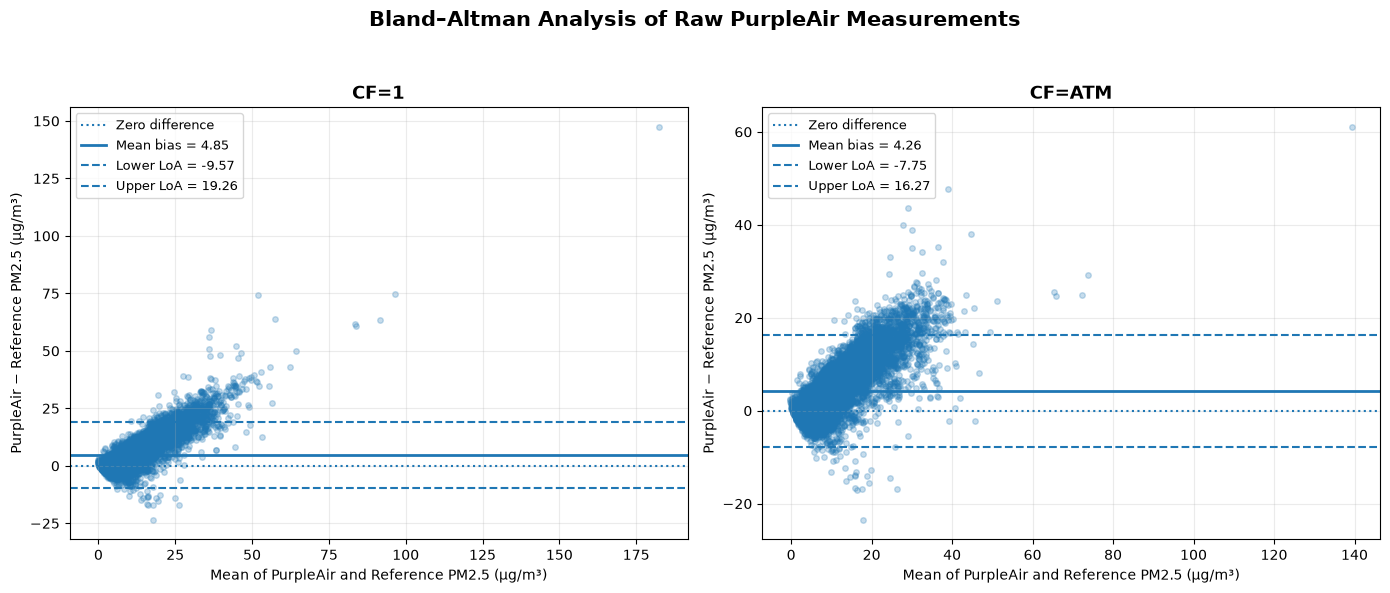

Figure saved to: reports/figures/dataset_a_bland_altman.png


In [187]:

# Calculate the average of the paired measurements
ba_data = pd.DataFrame(index=df_24hr.index)

ba_data["CF1_mean"] = (
    df_24hr["PM25cf1"] + df_24hr["PM25FM"]
) / 2

ba_data["CF1_difference"] = paired_differences["CF1_difference"]

ba_data["CFATM_mean"] = (
    df_24hr["PM25cfatm"] + df_24hr["PM25FM"]
) / 2

ba_data["CFATM_difference"] = paired_differences["CFATM_difference"]

# Create two-panel Bland–Altman figure
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

plot_settings = [
    ("CF=1", "CF1_mean", "CF1_difference", 0),
    ("CF=ATM", "CFATM_mean", "CFATM_difference", 1)
]

for ax, (label, mean_col, diff_col, result_idx) in zip(
    axes, plot_settings
):
    mean_values = ba_data[mean_col]
    differences = ba_data[diff_col]

    bias = bland_altman_results.loc[result_idx, "Mean_Bias"]
    lower = bland_altman_results.loc[
        result_idx, "Lower_Limit_of_Agreement"
    ]
    upper = bland_altman_results.loc[
        result_idx, "Upper_Limit_of_Agreement"
    ]

    ax.scatter(
        mean_values,
        differences,
        alpha=0.25,
        s=16
    )

    ax.axhline(0, linestyle=":", linewidth=1.5,
               label="Zero difference")
    ax.axhline(bias, linewidth=2,
               label=f"Mean bias = {bias:.2f}")
    ax.axhline(lower, linestyle="--", linewidth=1.5,
               label=f"Lower LoA = {lower:.2f}")
    ax.axhline(upper, linestyle="--", linewidth=1.5,
               label=f"Upper LoA = {upper:.2f}")

    ax.set_title(label, fontsize=13, fontweight="bold")
    ax.set_xlabel("Mean of PurpleAir and Reference PM2.5 (µg/m³)")
    ax.set_ylabel("PurpleAir − Reference PM2.5 (µg/m³)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

fig.suptitle(
    "Bland–Altman Analysis of Raw PurpleAir Measurements",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.94])

figure_path = FIGURES_DIR / "dataset_a_bland_altman.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", figure_path.resolve())

**Figure.** Bland–Altman plots comparing raw PurpleAir CF=1 and CF=ATM measurements with reference-monitor PM2.5 concentrations in Dataset A. The solid line represents mean bias, dashed lines represent conventional 95% limits of agreement, and the dotted line represents zero difference.

**Findings — Bland–Altman Agreement Analysis**

The Bland–Altman analysis shows positive average bias for both raw PurpleAir measurement types, indicating that they overestimate reference-monitor PM2.5 concentrations on average.

CF=1 has a mean bias of 4.845 µg/m³, with limits of agreement from −9.570 to 19.261 µg/m³. CF=ATM has a mean bias of 4.259 µg/m³, with limits from −7.747 to 16.265 µg/m³.

CF=ATM has narrower limits of agreement, indicating less overall dispersion in paired measurement differences. Both plots also suggest that disagreement becomes more positive and more variable as the average measurement concentration increases.

These conventional limits are descriptive because the dataset contains repeated observations within sites and site-dates. They should not be interpreted as independent-observation population limits.

In [188]:
# Calculate correlation between average measurement and paired difference.

from scipy.stats import spearmanr

ba_correlation_results = []

for measurement, mean_col, diff_col in [
    ("CF=1", "CF1_mean", "CF1_difference"),
    ("CF=ATM", "CFATM_mean", "CFATM_difference")
]:
    valid = ba_data[[mean_col, diff_col]].dropna()

    rho, p_value = spearmanr(
        valid[mean_col],
        valid[diff_col]
    )

    ba_correlation_results.append({
        "Measurement": measurement,
        "Observations": len(valid),
        "Spearman_rho": rho,
        "p_value": p_value
    })

pd.DataFrame(ba_correlation_results).round(4)

,Measurement,Observations,Spearman_rho,p_value
0,CF=1,12430,0.7945,0.0
1,CF=ATM,12430,0.7793,0.0


**Additional finding — Concentration-related agreement pattern**

The average measurement level was strongly positively associated with the PurpleAir-minus-reference difference for both CF=1 (Spearman ρ = 0.7945) and CF=ATM (ρ = 0.7793). This supports the visual observation that disagreement tends to become more positive at higher measurement levels.

However, the average and difference share the same underlying measurements, creating mathematical coupling. These correlations are therefore interpreted descriptively and are not independent evidence of proportional bias.

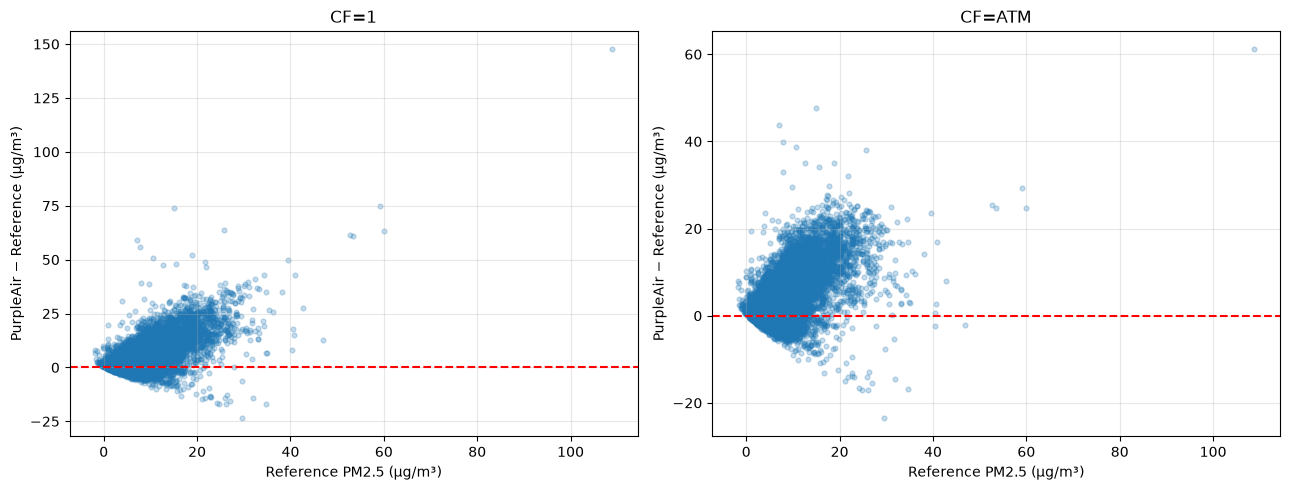

In [189]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, column, title in zip(
    axes,
    ["CF1_difference", "CFATM_difference"],
    ["CF=1", "CF=ATM"]
):
    ax.scatter(
        df_24hr["PM25FM"],
        paired_differences[column],
        alpha=0.25,
        s=12
    )
    ax.axhline(0, linestyle="--", color="red")
    ax.set_title(title)
    ax.set_xlabel("Reference PM2.5 (µg/m³)")
    ax.set_ylabel("PurpleAir − Reference (µg/m³)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "dataset_a_error_vs_reference.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Findings — Error Patterns Across PM2.5 Concentrations

The error scatterplots suggest that:

- Both raw PurpleAir measurements frequently overestimate reference PM2.5.
- Error variability increases as reference concentrations increase.
- CF=1 shows a wider spread of errors than CF=ATM.
- Both measurements contain substantial positive and negative errors at higher concentrations.

**Interpretation:** Measurement error appears to depend on PM2.5 concentration rather than remaining constant across the observed range. This pattern will be examined quantitatively using concentration groups.


In [190]:
# Group observations by reference PM2.5 concentration.
bins = [-float("inf"), 5, 10, 15, 20, 30, 50, float("inf")]

df_error_analysis = paired_differences.copy()

df_error_analysis["Reference_PM25"] = df_24hr["PM25FM"]

df_error_analysis["Concentration_Range"] = pd.cut(
    df_error_analysis["Reference_PM25"],
    bins=bins
)

# Summarize error by concentration range.
concentration_error = df_error_analysis.groupby(
    "Concentration_Range",
    observed=False
).agg(
    observations=("CF1_difference", "count"),
    CF1_mean_bias=("CF1_difference", "mean"),
    CF1_MAE=("CF1_difference", lambda x: x.abs().mean()),
    CFATM_mean_bias=("CFATM_difference", "mean"),
    CFATM_MAE=("CFATM_difference", lambda x: x.abs().mean())
)

concentration_error.round(3)

,observations,CF1_mean_bias,CF1_MAE,CFATM_mean_bias,CFATM_MAE
Concentration_Range,,,,,
"(-inf, 5.0]",3324,0.961,1.925,0.929,1.899
"(5.0, 10.0]",5395,2.916,4.109,2.802,4.003
"(10.0, 15.0]",2383,8.511,9.205,7.839,8.542
"(15.0, 20.0]",846,13.863,14.378,11.647,12.172
"(20.0, 30.0]",435,18.353,19.368,13.097,14.141
"(30.0, 50.0]",42,21.397,22.870,8.075,10.039
"(50.0, inf]",5,81.599,81.599,33.088,33.088


## Findings — Error Across PM2.5 Concentration Ranges

Both raw PurpleAir measurements show increasing positive bias and absolute error as reference PM2.5 concentration increases.

CF=ATM has lower MAE than CF=1 across all seven concentration groups.

The difference becomes more noticeable at higher concentrations. However, the 30–50 µg/m³ group contains only 42 observations, and the above-50 µg/m³ group contains only five observations. Results in these groups should therefore be interpreted cautiously.

**Interpretation:** Raw measurement error is concentration-dependent, and CF=ATM performs better in this initial comparison. Further evaluation across reference-monitor categories, sites, and regions is needed before drawing broader conclusions.

In [191]:
# Compare raw measurement errors by reference method.
method_error = pd.DataFrame({
    "FEMorFRM": df_24hr["FEMorFRM"],
    "CF1_difference": paired_differences["CF1_difference"],
    "CFATM_difference": paired_differences["CFATM_difference"]
})

method_summary = method_error.groupby("FEMorFRM").agg(
    observations=("CF1_difference", "count"),
    CF1_bias=("CF1_difference", "mean"),
    CF1_MAE=("CF1_difference", lambda x: x.abs().mean()),
    CFATM_bias=("CFATM_difference", "mean"),
    CFATM_MAE=("CFATM_difference", lambda x: x.abs().mean())
)

method_summary.round(3)

,observations,CF1_bias,CF1_MAE,CFATM_bias,CFATM_MAE
FEMorFRM,,,,,
FEM,10087,4.305,5.399,3.771,4.875
FRM,2343,7.172,7.684,6.359,6.883


## Findings — Measurement Errors by Reference Method

Raw PurpleAir measurement errors are higher for FRM observations than FEM observations.

- FEM MAE: 5.399 µg/m³ for CF=1 and 4.875 µg/m³ for CF=ATM.
- FRM MAE: 7.684 µg/m³ for CF=1 and 6.883 µg/m³ for CF=ATM.
- CF=ATM has lower MAE and positive bias for both reference categories.
- The FRM group contains fewer observations than the FEM group.

**Interpretation:** Measurement errors differ between the FEM and FRM subsets. These differences may also reflect site and concentration composition, so they should not be attributed to reference method alone.

In [192]:
# Compare measurement errors by region.
region_error = pd.DataFrame({
    "region": df_24hr["region"],
    "CF1_difference": paired_differences["CF1_difference"],
    "CFATM_difference": paired_differences["CFATM_difference"]
})

region_summary = region_error.groupby("region").agg(
    observations=("CF1_difference", "count"),
    CF1_bias=("CF1_difference", "mean"),
    CF1_MAE=("CF1_difference", lambda x: x.abs().mean()),
    CFATM_bias=("CFATM_difference", "mean"),
    CFATM_MAE=("CFATM_difference", lambda x: x.abs().mean())
)

region_summary.round(3)

,observations,CF1_bias,CF1_MAE,CFATM_bias,CFATM_MAE
region,,,,,
Alaska,369,1.546,2.809,0.821,2.121
Central Southwest,1504,1.824,3.977,1.196,3.376
North,5762,7.505,7.845,6.693,7.037
Southeast,1033,5.445,5.865,5.263,5.684
West,3762,2.138,3.769,1.818,3.462


## Findings — Measurement Errors by Region

Measurement errors vary across the five regions.

- The North region has the highest MAE for both CF=1 (7.845 µg/m³) and CF=ATM (7.037 µg/m³).
- Alaska has the lowest MAE for both measurements.
- CF=ATM has lower MAE than CF=1 in every region.
- The North also has the largest positive mean bias for both measurements.

**Interpretation:** Raw PurpleAir measurement errors vary regionally. These differences may also reflect regional concentration distributions and site characteristics, which require further investigation.

In [193]:
regional_concentrations = df_24hr.groupby("region").agg(
    observations=("PM25FM", "count"),
    reference_mean=("PM25FM", "mean"),
    reference_median=("PM25FM", "median"),
    CF1_mean=("PM25cf1", "mean"),
    CFATM_mean=("PM25cfatm", "mean")
)

regional_concentrations.round(3)

,observations,reference_mean,reference_median,CF1_mean,CFATM_mean
region,,,,,
Alaska,369,7.549,4.400,9.096,8.370
Central Southwest,1504,9.115,7.523,10.939,10.312
North,5762,9.423,8.102,16.928,16.115
Southeast,1033,8.038,7.400,13.483,13.301
West,3762,7.118,6.500,9.256,8.936


## Findings — Regional PM2.5 Concentrations

Regional PM2.5 concentration distributions differ across the five regions.

- North has the highest mean reference concentration (9.423 µg/m³) and the highest raw PurpleAir means.
- Southeast has a relatively lower reference mean (8.038 µg/m³), while its raw PurpleAir means are higher (13.483 µg/m³ for CF=1 and 13.301 µg/m³ for CF=ATM).
- Alaska has the lowest reference median (4.400 µg/m³).
- West has the lowest mean reference concentration (7.118 µg/m³).
- CF=1 has a higher mean concentration than CF=ATM in every region.

**Interpretation:** Regional differences in raw measurement errors may partly reflect differences in PM2.5 concentration distributions. Further analysis is needed before attributing these differences to regional sensor behavior.

In [194]:
# Calculate measurement errors by PurpleAir site ID.
site_error = pd.DataFrame({
    "ID": df_24hr["ID"],
    "CF1_difference": paired_differences["CF1_difference"],
    "CFATM_difference": paired_differences["CFATM_difference"]
})

site_summary = site_error.groupby("ID").agg(
    observations=("CF1_difference", "count"),
    CF1_MAE=("CF1_difference", lambda x: x.abs().mean()),
    CFATM_MAE=("CFATM_difference", lambda x: x.abs().mean()),
    CF1_bias=("CF1_difference", "mean"),
    CFATM_bias=("CFATM_difference", "mean")
)

site_summary.sort_values("CFATM_MAE", ascending=False).round(3)

,observations,CF1_MAE,CFATM_MAE,CF1_bias,CFATM_bias
ID,,,,,
MT1,8,12.519,11.279,12.519,11.279
IA10,177,11.686,10.345,11.460,10.114
IA11,389,11.944,10.327,11.823,10.176
IA8,377,9.371,8.510,9.053,8.192
IA1,603,9.230,8.474,8.932,8.173
IA3,830,9.114,8.359,8.886,8.129
IA9,381,9.482,8.315,9.285,8.120
IA12,79,8.786,7.798,8.661,7.672
IA2,646,8.474,7.767,8.137,7.427


## Findings — Site-Level Measurement Errors

Measurement errors vary considerably across the 49 PurpleAir site IDs.

- Several Iowa sites, including IA10, IA11, IA8, IA1, and IA3, show relatively high MAE and positive bias.
- MT1 has the highest CF=ATM MAE (11.279 µg/m³), but this estimate is based on only eight observations.
- CF=ATM generally has lower MAE than CF=1, although exceptions exist, including AK2 and WI5.
- Some sites show low or negative mean bias, indicating that the direction of measurement error is not consistent across all sites.

**Interpretation:** Site-level differences are substantial and may contribute to the regional patterns observed earlier. Results from sites with very small sample sizes should be interpreted cautiously.

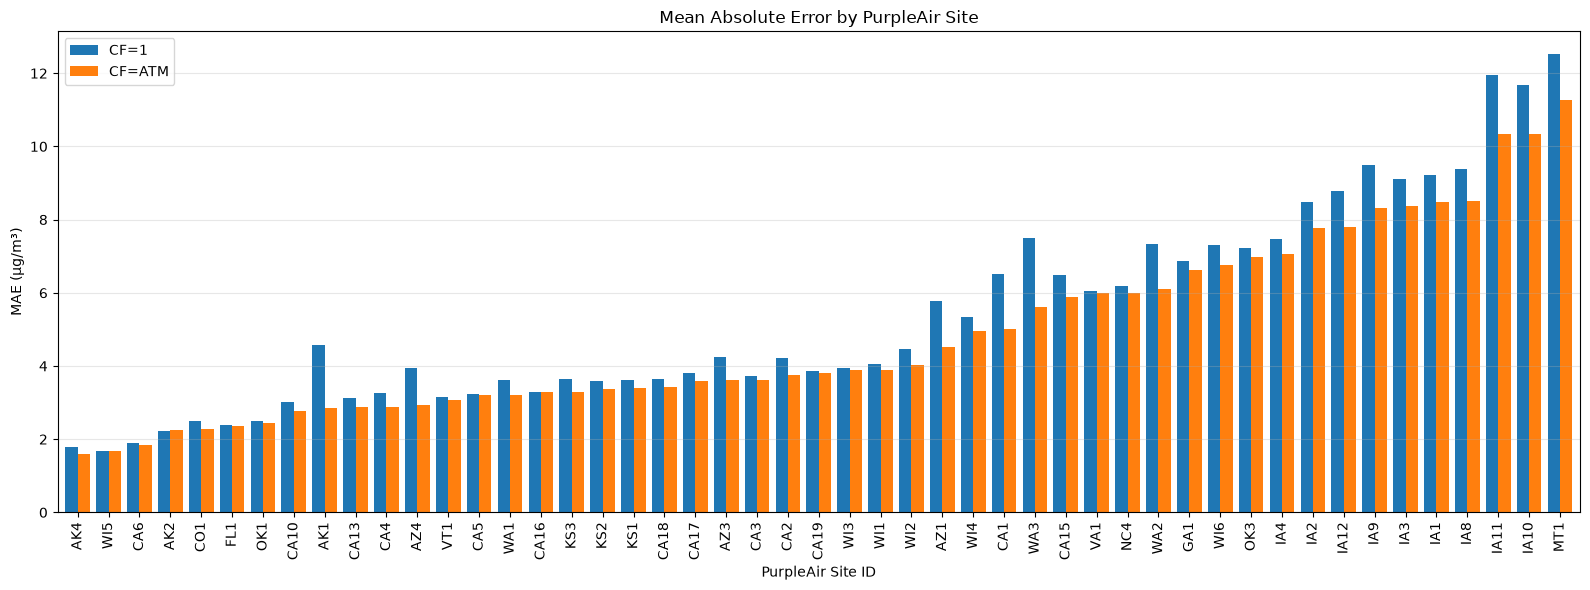

In [195]:
site_plot = site_summary.sort_values("CFATM_MAE")

ax = site_plot[["CF1_MAE", "CFATM_MAE"]].plot(
    kind="bar",
    figsize=(16, 6),
    width=0.8
)

ax.set_title("Mean Absolute Error by PurpleAir Site")
ax.set_xlabel("PurpleAir Site ID")
ax.set_ylabel("MAE (µg/m³)")
ax.legend(["CF=1", "CF=ATM"])
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "dataset_a_mae_by_site.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [196]:
environment_summary = df_24hr[
    ["RH", "TempC", "Dewpoint"]
].describe().T

environment_summary["missing_count"] = (
    df_24hr[["RH", "TempC", "Dewpoint"]].isna().sum()
)

environment_summary.round(2)

,count,mean,std,min,25%,50%,75%,max,missing_count
RH,12413.0,49.21,16.28,1.99,41.06,51.27,59.55,100.00,17
TempC,12246.0,18.34,11.00,-25.35,11.23,19.49,26.70,44.45,184
Dewpoint,12246.0,6.25,9.54,-35.76,0.05,7.06,13.23,28.36,184


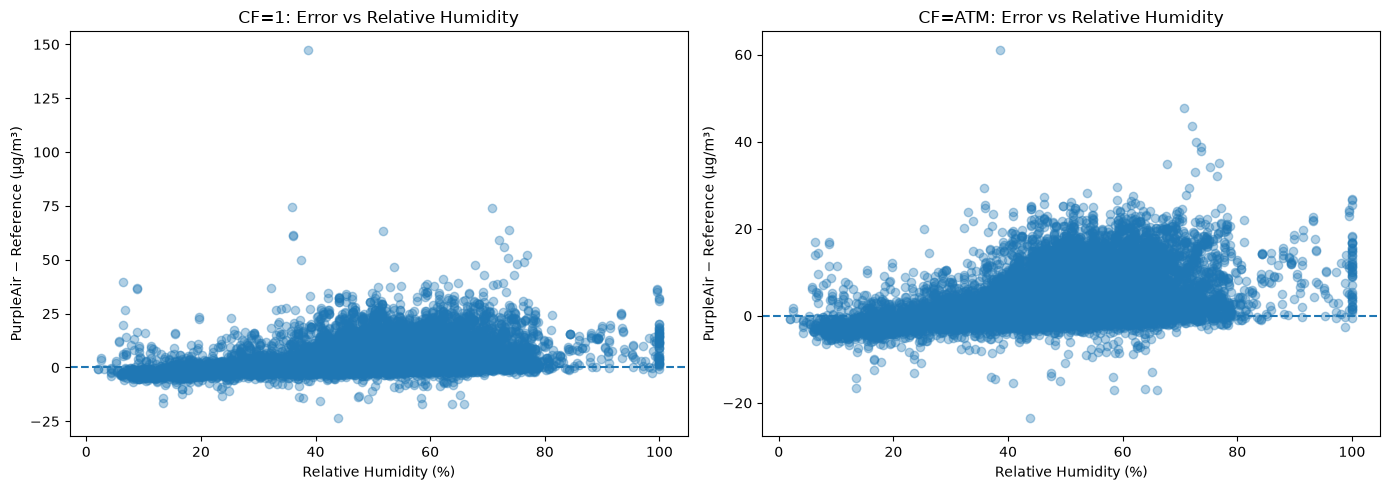

In [197]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    df_24hr["RH"],
    paired_differences["CF1_difference"],
    alpha=0.35
)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("CF=1: Error vs Relative Humidity")
axes[0].set_xlabel("Relative Humidity (%)")
axes[0].set_ylabel("PurpleAir − Reference (µg/m³)")

axes[1].scatter(
    df_24hr["RH"],
    paired_differences["CFATM_difference"],
    alpha=0.35
)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("CF=ATM: Error vs Relative Humidity")
axes[1].set_xlabel("Relative Humidity (%)")
axes[1].set_ylabel("PurpleAir − Reference (µg/m³)")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "dataset_a_error_vs_relative_humidity.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## Findings — Measurement Error vs Relative Humidity

The scatterplots suggest that measurement error varies with relative humidity.

- Errors generally become more positive and more widely dispersed as RH increases from low to moderate-high levels.
- CF=1 shows greater error variability and more extreme positive outliers than CF=ATM.
- At RH above approximately 80%, observations are relatively sparse, limiting interpretation.

**Interpretation:** Relative humidity may be an important predictor of measurement error. However, this exploratory relationship does not establish causation and may be influenced by reference concentration and site-level differences.

In [198]:
rh_data = pd.DataFrame({
    "RH": df_24hr["RH"],
    "CF1_difference": paired_differences["CF1_difference"],
    "CFATM_difference": paired_differences["CFATM_difference"]
})

rh_data["RH_range"] = pd.cut(
    rh_data["RH"],
    bins=[0, 20, 40, 60, 80, 100],
    include_lowest=True
)

rh_summary = rh_data.groupby("RH_range", observed=False).agg(
    observations=("RH", "count"),
    CF1_bias=("CF1_difference", "mean"),
    CF1_MAE=("CF1_difference", lambda x: x.abs().mean()),
    CFATM_bias=("CFATM_difference", "mean"),
    CFATM_MAE=("CFATM_difference", lambda x: x.abs().mean())
)

rh_summary.round(3)

,observations,CF1_bias,CF1_MAE,CFATM_bias,CFATM_MAE
RH_range,,,,,
"(-0.001, 20.0]",921,-1.543,3.108,-1.816,2.871
"(20.0, 40.0]",1977,1.445,3.208,0.929,2.710
"(40.0, 60.0]",6528,5.433,5.972,4.897,5.443
"(60.0, 80.0]",2811,7.711,8.033,6.861,7.187
"(80.0, 100.0]",176,9.243,9.360,8.539,8.657


## Findings — Measurement Errors Across Relative Humidity Ranges

Measurement errors increase substantially across higher RH ranges.

- At RH ≤20%, both methods show negative bias, indicating slight underestimation.
- Between 20% and 40% RH, bias becomes positive.
- From 40% to 80% RH, both bias and MAE increase considerably.
- The 80–100% RH group has the highest errors, but contains only 176 observations.
- CF=ATM has lower MAE than CF=1 across all five RH ranges.

**Interpretation:** The results support examining RH as a calibration predictor. However, RH may be associated with other factors, including reference concentration and site characteristics.

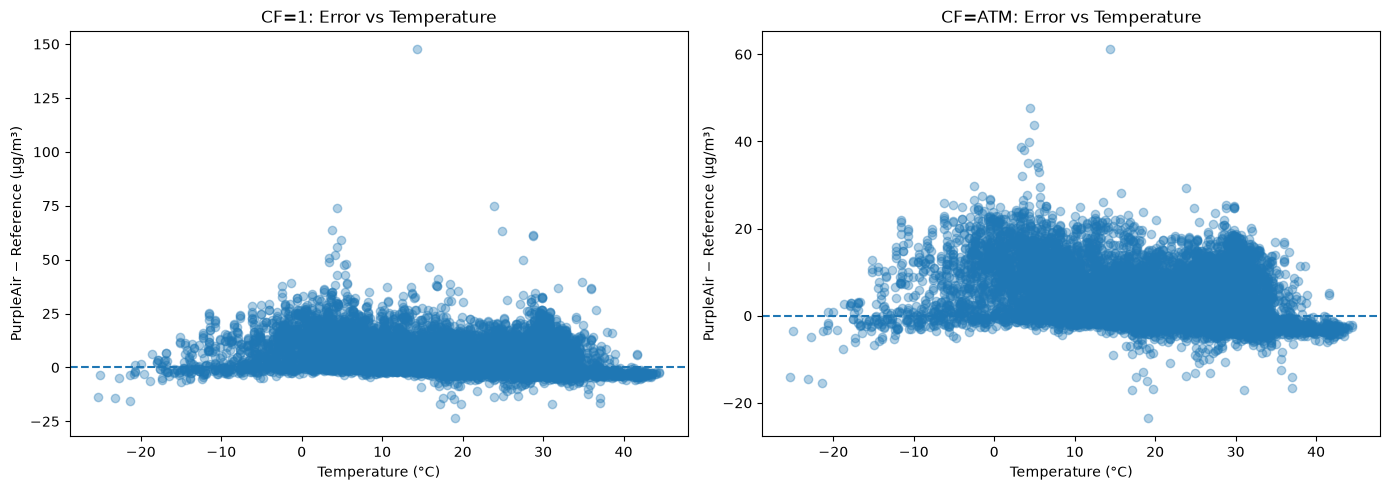

In [199]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    df_24hr["TempC"],
    paired_differences["CF1_difference"],
    alpha=0.35
)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("CF=1: Error vs Temperature")
axes[0].set_xlabel("Temperature (°C)")
axes[0].set_ylabel("PurpleAir − Reference (µg/m³)")

axes[1].scatter(
    df_24hr["TempC"],
    paired_differences["CFATM_difference"],
    alpha=0.35
)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("CF=ATM: Error vs Temperature")
axes[1].set_xlabel("Temperature (°C)")
axes[1].set_ylabel("PurpleAir − Reference (µg/m³)")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "dataset_a_error_vs_temperature.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Findings — Measurement Error vs Temperature

The scatterplots indicate a non-linear relationship between temperature and measurement error.

- Errors are predominantly positive across much of the moderate temperature range.
- Error patterns appear to decrease at higher temperatures, particularly above approximately 15–30°C.
- CF=1 shows greater variability and more extreme positive outliers than CF=ATM.
- Both methods show some negative errors, particularly at higher temperatures.

**Interpretation:** Temperature may provide additional calibration information, but its relationship with measurement error appears non-linear. Further analysis is needed before deciding whether temperature should be included as an independent predictor.

In [200]:
temp_data = pd.DataFrame({
    "TempC": df_24hr["TempC"],
    "CF1_difference": paired_differences["CF1_difference"],
    "CFATM_difference": paired_differences["CFATM_difference"]
})

temp_data["Temp_range"] = pd.cut(
    temp_data["TempC"],
    bins=[-float("inf"), 0, 10, 20, 30, float("inf")]
)

temp_summary = temp_data.groupby(
    "Temp_range", observed=False
).agg(
    observations=("TempC", "count"),
    CF1_bias=("CF1_difference", "mean"),
    CF1_MAE=("CF1_difference", lambda x: x.abs().mean()),
    CFATM_bias=("CFATM_difference", "mean"),
    CFATM_MAE=("CFATM_difference", lambda x: x.abs().mean())
)

temp_summary.round(3)

,observations,CF1_bias,CF1_MAE,CFATM_bias,CFATM_MAE
Temp_range,,,,,
"(-inf, 0.0]",786,7.997,8.885,7.322,8.226
"(0.0, 10.0]",1947,9.313,9.563,8.206,8.457
"(10.0, 20.0]",3618,3.945,4.671,3.375,4.112
"(20.0, 30.0]",4225,3.716,4.727,3.323,4.345
"(30.0, inf]",1670,2.987,5.424,2.503,4.958


## Findings — Measurement Errors Across Temperature Ranges

Measurement errors vary across temperature ranges, with the largest errors generally occurring below 10°C.

- Below 10°C, both CF=1 and CF=ATM show relatively high positive bias and MAE.
- Between 10°C and 30°C, bias and MAE decrease substantially.
- Above 30°C, bias decreases further, but MAE increases compared with the 10–30°C ranges, indicating greater dispersion around the average error.
- CF=ATM has lower bias and MAE than CF=1 in every temperature group.

**Interpretation:** Temperature may provide useful calibration information, but its relationship with error is not monotonic. Its incremental value beyond RH remains untested.

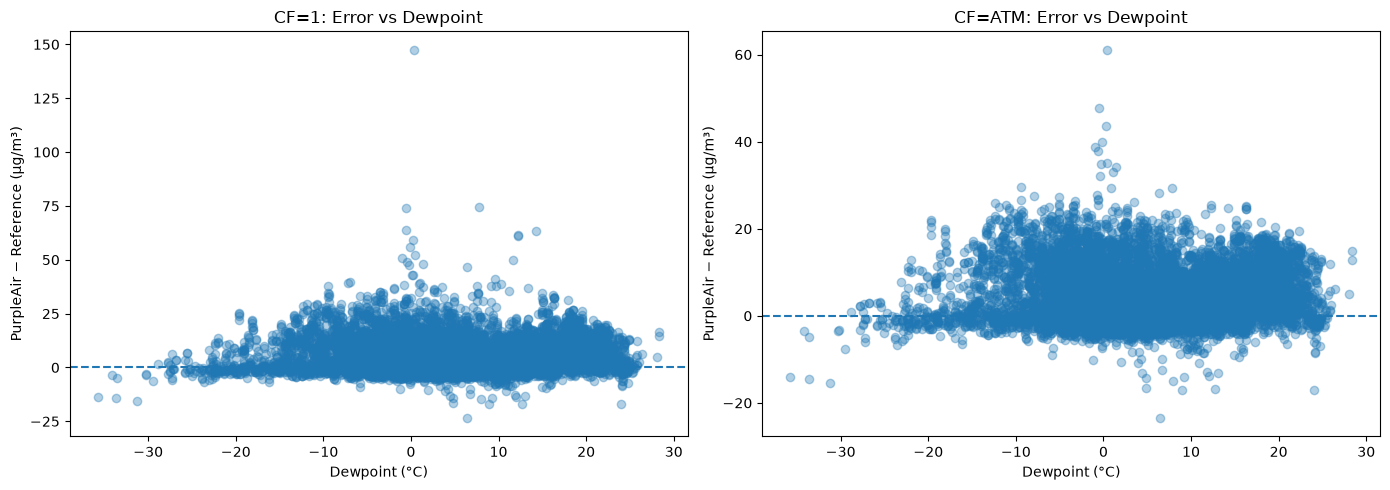

In [201]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    df_24hr["Dewpoint"],
    paired_differences["CF1_difference"],
    alpha=0.35
)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("CF=1: Error vs Dewpoint")
axes[0].set_xlabel("Dewpoint (°C)")
axes[0].set_ylabel("PurpleAir − Reference (µg/m³)")

axes[1].scatter(
    df_24hr["Dewpoint"],
    paired_differences["CFATM_difference"],
    alpha=0.35
)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("CF=ATM: Error vs Dewpoint")
axes[1].set_xlabel("Dewpoint (°C)")
axes[1].set_ylabel("PurpleAir − Reference (µg/m³)")

plt.tight_layout()
plt.show()

## Findings — Measurement Error vs Dewpoint

The scatterplots suggest a non-linear relationship between dewpoint and measurement error.

- Errors are predominantly positive across much of the observed dewpoint range.
- Both methods show considerable positive error and variability around moderate dewpoint values.
- Errors appear closer to zero at higher dewpoint values.
- CF=1 exhibits greater variability and more extreme positive outliers than CF=ATM.

**Interpretation:** Dewpoint may capture environmental information associated with measurement error. However, because it is derived from RH and temperature, its incremental predictive value needs to be evaluated rather than assumed.

In [202]:
correlation_data = pd.DataFrame({
    "RH": df_24hr["RH"],
    "TempC": df_24hr["TempC"],
    "Dewpoint": df_24hr["Dewpoint"],
    "CF1_error": paired_differences["CF1_difference"],
    "CFATM_error": paired_differences["CFATM_difference"]
})

correlation_data.corr(method="spearman").round(3)

,RH,TempC,Dewpoint,CF1_error,CFATM_error
RH,1.000,-0.386,0.215,0.428,0.442
TempC,-0.386,1.000,0.736,-0.240,-0.244
Dewpoint,0.215,0.736,1.000,0.060,0.065
CF1_error,0.428,-0.240,0.060,1.000,0.995
CFATM_error,0.442,-0.244,0.065,0.995,1.000


## Findings — Environmental Variable Correlations

Spearman correlation analysis indicates:

- RH has the strongest positive association with measurement error (0.428 for CF=1 and 0.442 for CF=ATM).
- Temperature has a negative association with measurement error (−0.240 and −0.244).
- Dewpoint has very weak associations with measurement error (0.060 and 0.065).
- Temperature and dewpoint are strongly correlated (0.736), indicating overlapping information.
- CF=1 and CF=ATM errors are highly correlated (0.995).

**Interpretation:** RH is the leading environmental predictor candidate. Temperature may add useful information, while dewpoint is a lower-priority candidate because of its overlap with temperature.

These are exploratory associations, not evidence of independent predictive value or causation.

## Temporal Patterns

In [203]:
# Parse dates and inspect the study period

df_24hr["Date_parsed"] = pd.to_datetime(
    df_24hr["Date"],
    format="%Y-%m-%d",
    errors="coerce"
)

print("Unparseable dates:", df_24hr["Date_parsed"].isna().sum())
print("Earliest date:", df_24hr["Date_parsed"].min())
print("Latest date:", df_24hr["Date_parsed"].max())
print("Unique dates:", df_24hr["Date_parsed"].nunique())

print("\nObservations by year:")
display(
    df_24hr.groupby(df_24hr["Date_parsed"].dt.year)
    .size()
    .rename("Observations")
    .to_frame()
)

print("\nObservations by month:")
display(
    df_24hr.groupby(df_24hr["Date_parsed"].dt.to_period("M"))
    .size()
    .rename("Observations")
    .to_frame()
)

Unparseable dates: 0
Earliest date: 2017-09-30 00:00:00
Latest date: 2020-01-13 00:00:00
Unique dates: 830

Observations by year:


,Observations
Date_parsed,
2017,241
2018,3502
2019,8642
2020,45



Observations by month:


,Observations
Date_parsed,
2017-09,1
2017-10,41
2017-11,69
2017-12,130
2018-01,132
2018-02,97
2018-03,148
2018-04,207
2018-05,352


**Findings — Date Coverage and Observation Distribution**

Dataset A covers September 30, 2017, through January 13, 2020, with 830 unique dates and no missing or unparseable date values.

The observations are unevenly distributed across years:

- 2017: 241 observations.
- 2018: 3,502 observations.
- 2019: 8,642 observations.
- 2020: 45 observations.

Most observations come from 2018 and 2019. Monthly observation counts also vary considerably, indicating uneven temporal coverage.

**Interpretation:** The dataset provides observations across multiple years, but the uneven distribution means that apparent monthly or seasonal patterns must be interpreted cautiously. Differences over time may reflect changes in site participation or data availability rather than changes in sensor performance.

In [204]:
# Examine monthly observation coverage

monthly_coverage = (
    df_24hr
    .groupby(df_24hr["Date_parsed"].dt.to_period("M"))
    .agg(
        Observations=("PM25FM", "size"),
        Unique_Sites=("ID", "nunique"),
        Mean_Reference=("PM25FM", "mean")
    )
)

display(monthly_coverage.round(2))

,Observations,Unique_Sites,Mean_Reference
Date_parsed,,,
2017-09,1,1,3.50
2017-10,41,2,8.07
2017-11,69,3,9.49
2017-12,130,4,11.45
2018-01,132,4,8.06
2018-02,97,4,8.17
2018-03,148,6,5.44
2018-04,207,8,6.32
2018-05,352,11,6.96


### Monthly Measurement-Error Patterns

Monthly measurement errors are examined to assess whether agreement between raw PurpleAir measurements and reference monitors varies over the study period.

For each month, the analysis compares CF=1 and CF=ATM using mean absolute error (MAE) and mean bias. Observation counts and participating sites are also reported to help identify changes in temporal coverage and sample composition.

These monthly summaries are descriptive. Differences may reflect changes in participating sites, reference concentration levels, and observation volume rather than temporal changes in sensor performance.

In [205]:
# Calculate monthly measurement-error metrics

temporal_data = pd.DataFrame(index=df_24hr.index)

temporal_data["Date_parsed"] = df_24hr["Date_parsed"]
temporal_data["ID"] = df_24hr["ID"]
temporal_data["PM25FM"] = df_24hr["PM25FM"]
temporal_data["CF1_error"] = paired_differences["CF1_difference"]
temporal_data["CFATM_error"] = paired_differences["CFATM_difference"]

temporal_data["Month"] = (
    temporal_data["Date_parsed"].dt.to_period("M")
)

monthly_error_summary = (
    temporal_data
    .groupby("Month")
    .agg(
        Observations=("PM25FM", "size"),
        Unique_Sites=("ID", "nunique"),
        Mean_Reference=("PM25FM", "mean"),
        CF1_MAE=("CF1_error", lambda x: x.abs().mean()),
        CFATM_MAE=("CFATM_error", lambda x: x.abs().mean()),
        CF1_Bias=("CF1_error", "mean"),
        CFATM_Bias=("CFATM_error", "mean")
    )
)

display(monthly_error_summary.round(3))

,Observations,Unique_Sites,Mean_Reference,CF1_MAE,CFATM_MAE,CF1_Bias,CFATM_Bias
Month,,,,,,,
2017-09,1,1,3.500,0.826,0.826,0.826,0.826
2017-10,41,2,8.066,4.410,3.957,3.769,3.303
2017-11,69,3,9.487,8.534,7.776,7.862,7.099
2017-12,130,4,11.454,13.069,10.506,12.250,9.686
2018-01,132,4,8.065,9.196,8.139,8.813,7.748
2018-02,97,4,8.173,8.417,7.467,8.129,7.178
2018-03,148,6,5.441,4.372,4.168,3.683,3.478
2018-04,207,8,6.325,2.933,2.784,1.075,0.923
2018-05,352,11,6.956,5.180,4.883,4.344,4.045


**Findings — Monthly Measurement-Error Patterns**

Monthly MAE was lower for CF=ATM than CF=1 in 28 of the 29 observed months. September 2017 had identical MAE for both measurements, based on only one observation.

Both measurement types showed positive monthly mean bias throughout the study period, indicating average overestimation of reference-monitor PM2.5 concentrations.

Measurement errors varied substantially across months. For example, CF=1 MAE ranged from 2.933 µg/m³ in April 2018 to 13.069 µg/m³ in December 2017. CF=ATM MAE ranged from 2.784 µg/m³ in April 2018 to 10.506 µg/m³ in December 2017.

These changes occurred alongside substantial variation in monthly reference concentrations, observation counts, and participating sites.

**Interpretation:** The monthly summaries suggest that the relative advantage of CF=ATM over CF=1 is generally consistent, but the magnitude of measurement error varies over time. These pooled comparisons cannot distinguish temporal changes in sensor performance from changes in site participation, concentration levels, and sample composition. They do not establish seasonal effects or within-site temporal trends.

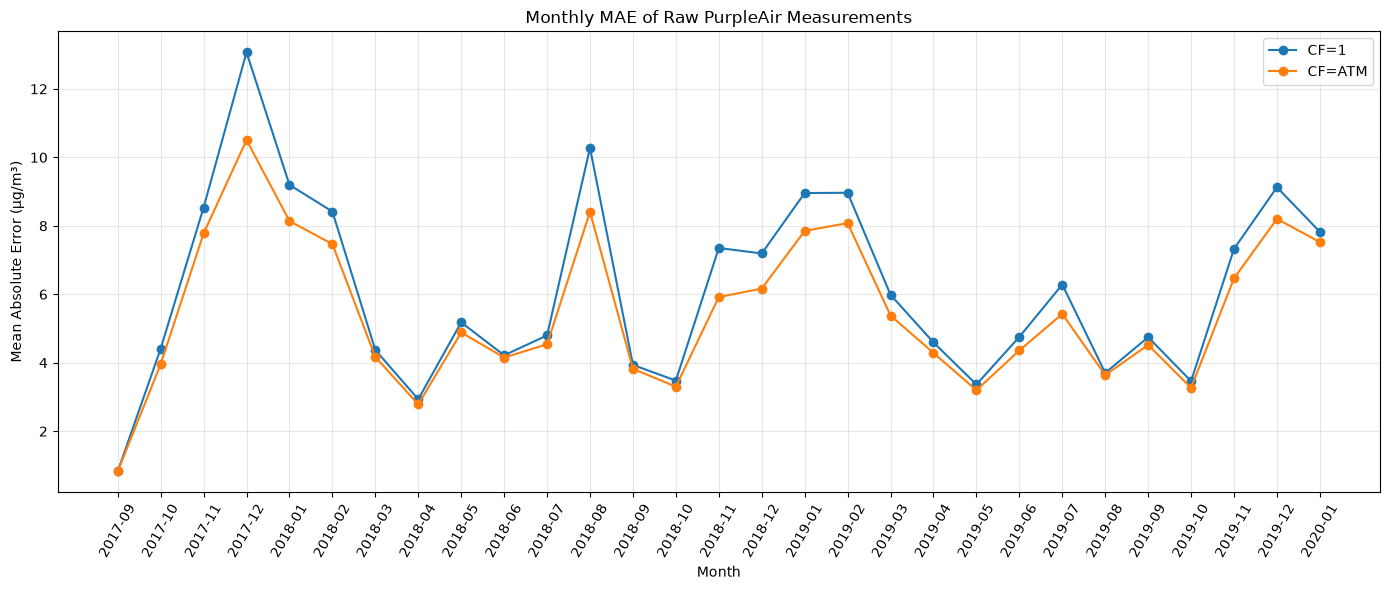

Figure saved to: reports/figures/dataset_a_monthly_mae.png


In [206]:
# Plot monthly MAE for CF=1 and CF=ATM

fig, ax = plt.subplots(figsize=(14, 6))

monthly_error_summary.index = (
    monthly_error_summary.index.astype("period[M]")
)

ax.plot(
    monthly_error_summary.index.astype(str),
    monthly_error_summary["CF1_MAE"],
    marker="o",
    label="CF=1"
)

ax.plot(
    monthly_error_summary.index.astype(str),
    monthly_error_summary["CFATM_MAE"],
    marker="o",
    label="CF=ATM"
)

ax.set_title("Monthly MAE of Raw PurpleAir Measurements")
ax.set_xlabel("Month")
ax.set_ylabel("Mean Absolute Error (µg/m³)")
ax.tick_params(axis="x", rotation=60)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()

figure_path = FIGURES_DIR / "dataset_a_monthly_mae.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure_path.resolve())

**Figure .** Monthly mean absolute error (MAE) of raw PurpleAir CF=1 and CF=ATM measurements compared with reference-monitor PM2.5 concentrations in Dataset A, September 2017–January 2020. CF=ATM has lower or equal monthly MAE throughout the observed period. Monthly variation should be interpreted in light of changing observation counts, site participation, and reference concentrations.

### Within-Site Temporal Consistency

The pooled monthly analysis may reflect changes in site participation rather than changes within individual sites. This section examines monthly measurement error among sites with repeated observations across the study period.

The comparison will help assess whether the pooled temporal pattern is also visible within sites. It remains descriptive and does not establish seasonal effects or causal changes in sensor performance.

In [207]:
# Examine the number of months with observations per site

site_month_coverage = (
    temporal_data
    .groupby("ID")
    .agg(
        Observations=("PM25FM", "size"),
        Unique_Months=("Month", "nunique")
    )
    .sort_values("Unique_Months", ascending=False)
)

print("Number of sites:", len(site_month_coverage))
print("\nSites by number of observed months:")
display(
    site_month_coverage["Unique_Months"]
    .value_counts()
    .sort_index()
    .rename_axis("Observed_Months")
    .to_frame("Number_of_Sites")
)

print("\nSite coverage summary:")
display(site_month_coverage.describe().round(2))

Number of sites: 49

Sites by number of observed months:


,Number_of_Sites
Observed_Months,
1,2
2,1
3,4
4,6
5,3
6,3
7,5
8,1
9,2



Site coverage summary:


,Observations,Unique_Months
count,49.00,49.00
mean,253.67,9.82
std,207.14,6.74
min,3.00,1.00
25%,111.00,4.00
50%,184.00,8.00
75%,384.00,13.00
max,830.00,29.00


**Findings — Site-Level Temporal Coverage**

The dataset contains 49 sites with substantially different temporal coverage.

- Median site coverage: 8 distinct months.
- Mean site coverage: 9.82 distinct months.
- Minimum coverage: 1 month.
- Maximum coverage: 29 months.
- 18 of 49 sites have observations in at least 12 distinct months.

The uneven coverage indicates that pooled monthly summaries combine sites with different observation periods and participation histories.

**Analytical decision:** For the next within-site temporal comparison, use sites with observations in at least 12 distinct months. This provides a minimum of approximately one year of observed monthly coverage while retaining a subset of sites for comparison. The 12 months do not have to be consecutive, and the resulting subset may not represent all 49 sites.

In [208]:
# Identify sites with at least 12 observed months

eligible_sites = (
    site_month_coverage
    .loc[site_month_coverage["Unique_Months"] >= 12]
    .index
)

print("Eligible sites:", len(eligible_sites))
print("\nEligible site IDs:")
print(sorted(eligible_sites.tolist()))

# Retain observations from eligible sites
temporal_data_eligible = temporal_data[
    temporal_data["ID"].isin(eligible_sites)
].copy()

print("\nEligible-site observations:", len(temporal_data_eligible))
print(
    "Eligible-site months:",
    temporal_data_eligible["Month"].nunique()
)

Eligible sites: 18

Eligible site IDs:
['AZ3', 'AZ4', 'CA1', 'CA10', 'CA13', 'CA17', 'CA18', 'CA2', 'CA4', 'IA1', 'IA11', 'IA2', 'IA3', 'IA4', 'IA8', 'IA9', 'NC4', 'WA1']

Eligible-site observations: 8311
Eligible-site months: 29


In [209]:
# Calculate monthly measurement errors for eligible sites

monthly_error_eligible = (
    temporal_data_eligible
    .groupby("Month")
    .agg(
        Observations=("PM25FM", "size"),
        Unique_Sites=("ID", "nunique"),
        Mean_Reference=("PM25FM", "mean"),
        CF1_MAE=("CF1_error", lambda x: x.abs().mean()),
        CFATM_MAE=("CFATM_error", lambda x: x.abs().mean()),
        CF1_Bias=("CF1_error", "mean"),
        CFATM_Bias=("CFATM_error", "mean")
    )
)

display(monthly_error_eligible.round(3))

,Observations,Unique_Sites,Mean_Reference,CF1_MAE,CFATM_MAE,CF1_Bias,CFATM_Bias
Month,,,,,,,
2017-09,1,1,3.500,0.826,0.826,0.826,0.826
2017-10,41,2,8.066,4.410,3.957,3.769,3.303
2017-11,69,3,9.487,8.534,7.776,7.862,7.099
2017-12,102,3,11.953,9.565,8.067,8.521,7.021
2018-01,101,3,9.348,8.661,7.799,8.171,7.298
2018-02,69,3,9.663,9.883,8.902,9.690,8.708
2018-03,117,5,5.510,3.989,3.920,3.327,3.257
2018-04,177,7,6.781,3.014,2.849,0.886,0.718
2018-05,291,9,7.850,5.368,5.019,4.368,4.017


**Findings — Monthly Errors Within Sites With Extended Coverage**

Restricting the analysis to 18 sites with observations in at least 12 distinct months produced a broadly similar monthly error pattern to the full Dataset A analysis.

CF=ATM had lower MAE than CF=1 in 27 of the 28 months; September 2017 had equal MAE based on one observation. Both measurements continued to show positive monthly mean bias throughout the observed period.

Higher-error periods remained visible in the restricted subset, including December 2017, August 2018, January–February 2019, and November–December 2019.

**Interpretation:** The broad monthly pattern persists when sites with limited overall temporal coverage are excluded. This suggests that the pooled pattern is not explained entirely by sites with short observation histories.

However, this is not a fully balanced site-month panel. The number of participating eligible sites still varies by month. Consequently, changing site composition and within-site observation counts may continue to influence the monthly summaries. These results do not establish seasonal effects or temporal changes in sensor performance.

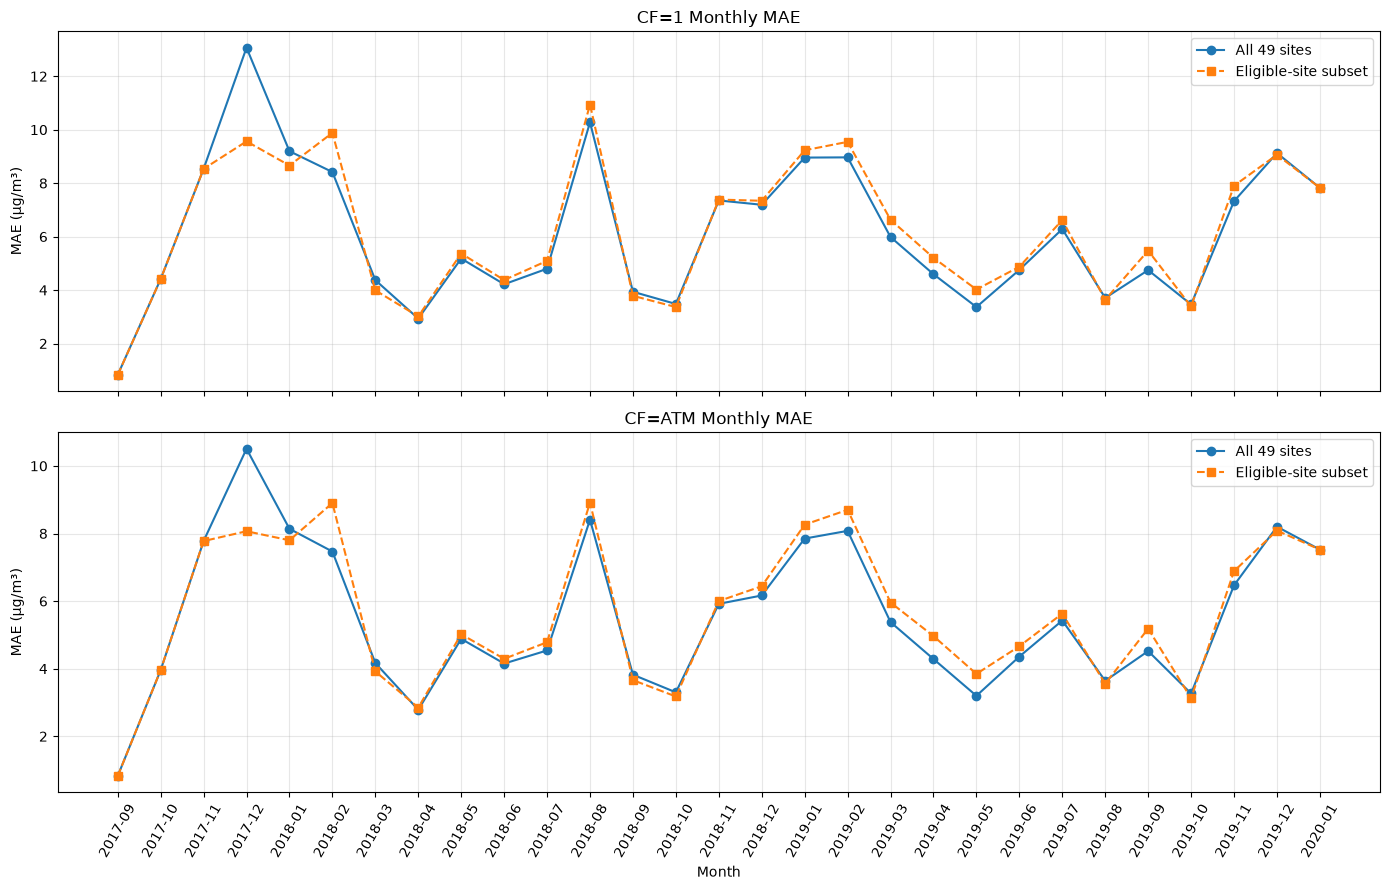

Figure saved to: reports/figures/dataset_a_monthly_mae_site_subset_comparison.png


In [210]:
# Compare pooled and eligible-site monthly MAE

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

for ax, metric, title in [
    (axes[0], "CF1_MAE", "CF=1 Monthly MAE"),
    (axes[1], "CFATM_MAE", "CF=ATM Monthly MAE")
]:
    ax.plot(
        monthly_error_summary.index.astype(str),
        monthly_error_summary[metric],
        marker="o",
        label="All 49 sites"
    )

    ax.plot(
        monthly_error_eligible.index.astype(str),
        monthly_error_eligible[metric],
        marker="s",
        linestyle="--",
        label="Eligible-site subset"
    )

    ax.set_title(title)
    ax.set_ylabel("MAE (µg/m³)")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[1].set_xlabel("Month")
axes[1].tick_params(axis="x", rotation=60)

plt.tight_layout()

figure_path = FIGURES_DIR / "dataset_a_monthly_mae_site_subset_comparison.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure_path.resolve())

**Figure .** Comparison of monthly MAE using all 49 Dataset A sites and the subset of 18 sites with observations in at least 12 distinct months. The broad temporal pattern remains similar between the two analyses, although some monthly estimates differ. The restricted subset is not a fully balanced panel because site participation and observation counts still vary by month.

**Temporal Analysis — Overall Conclusion**

Dataset A contains observations across 830 dates from September 2017 through January 2020, with substantial variation in monthly observation counts and participating sites.

Monthly MAE summaries show that CF=ATM has lower or equal MAE than CF=1 throughout the observed months. Both measurement types exhibit positive monthly mean bias, while the magnitude of error varies over time.

Restricting the analysis to 18 sites with observations in at least 12 distinct months produces a broadly similar temporal pattern. This indicates that the observed pattern is not explained entirely by sites with limited overall temporal coverage.

However, the restricted analysis is not a balanced site-month panel. Changes in participating sites, observation counts, and reference concentrations may still influence monthly results. Therefore, these analyses do not establish seasonal effects or causal temporal changes in sensor performance.

For subsequent modeling, temporal grouping should be considered when designing validation splits, particularly if the goal is to evaluate performance on future observations.

In [211]:
import numpy as np

# Absolute errors for each paired observation
bootstrap_data = pd.DataFrame({
    "ID": df_24hr["ID"],
    "Date": df_24hr["Date"],
    "CF1_abs_error": paired_differences["CF1_difference"].abs(),
    "CFATM_abs_error": paired_differences["CFATM_difference"].abs()
})

# Aggregate repeated observations within each site-date cluster
cluster_data = bootstrap_data.groupby(
    ["ID", "Date"]
).agg(
    CF1_error_sum=("CF1_abs_error", "sum"),
    CFATM_error_sum=("CFATM_abs_error", "sum"),
    observations=("CF1_abs_error", "count")
).reset_index()

# Observed difference: positive means CF=ATM has lower MAE
observed_difference = (
    cluster_data["CF1_error_sum"].sum()
    - cluster_data["CFATM_error_sum"].sum()
) / cluster_data["observations"].sum()

# Bootstrap by resampling complete site-date clusters
rng = np.random.default_rng(42)
n_clusters = len(cluster_data)
bootstrap_differences = []

for _ in range(2000):
    sampled_indices = rng.integers(0, n_clusters, size=n_clusters)
    sampled = cluster_data.iloc[sampled_indices]

    difference = (
        sampled["CF1_error_sum"].sum()
        - sampled["CFATM_error_sum"].sum()
    ) / sampled["observations"].sum()

    bootstrap_differences.append(difference)

ci_lower, ci_upper = np.percentile(
    bootstrap_differences, [2.5, 97.5]
)

print(f"Site-date clusters: {n_clusters:,}")
print(f"Observations: {cluster_data['observations'].sum():,}")
print(f"Observed MAE difference (CF1 - CFATM): {observed_difference:.3f}")
print(f"95% bootstrap confidence interval: [{ci_lower:.3f}, {ci_upper:.3f}]")
print(
    "Bootstrap proportion above zero:",
    f"{np.mean(np.array(bootstrap_differences) > 0):.3f}"
)

Site-date clusters: 9,707
Observations: 12,430
Observed MAE difference (CF1 - CFATM): 0.576
95% bootstrap confidence interval: [0.532, 0.622]
Bootstrap proportion above zero: 1.000


In [212]:
# Aggregate site-date results into 49 site-level clusters
site_bootstrap_data = cluster_data.groupby("ID").agg(
    CF1_error_sum=("CF1_error_sum", "sum"),
    CFATM_error_sum=("CFATM_error_sum", "sum"),
    observations=("observations", "sum")
).reset_index()

rng = np.random.default_rng(42)
n_sites = len(site_bootstrap_data)
site_bootstrap_differences = []

for _ in range(5000):
    sampled_indices = rng.integers(0, n_sites, size=n_sites)
    sampled = site_bootstrap_data.iloc[sampled_indices]

    difference = (
        sampled["CF1_error_sum"].sum()
        - sampled["CFATM_error_sum"].sum()
    ) / sampled["observations"].sum()

    site_bootstrap_differences.append(difference)

site_ci_lower, site_ci_upper = np.percentile(
    site_bootstrap_differences, [2.5, 97.5]
)

print(f"Sites: {n_sites}")
print(f"Observed MAE difference: {observed_difference:.3f}")
print(
    f"95% site-level bootstrap CI: "
    f"[{site_ci_lower:.3f}, {site_ci_upper:.3f}]"
)
print(
    "Bootstrap proportion above zero:",
    f"{np.mean(np.array(site_bootstrap_differences) > 0):.3f}"
)

Sites: 49
Observed MAE difference: 0.576
95% site-level bootstrap CI: [0.444, 0.715]
Bootstrap proportion above zero: 1.000


## Validation — CF=ATM vs CF=1 MAE Improvement

CF=ATM has lower overall MAE than CF=1 in the 24-hour collocation dataset.

- CF=1 MAE: 5.829 µg/m³
- CF=ATM MAE: 5.254 µg/m³
- Absolute improvement: 0.576 µg/m³ (approximately 9.9%).
- A site-level bootstrap using 5,000 resamples across 49 sites produced a 95% confidence interval of 0.444–0.715 µg/m³.

**Conclusion:** The observed MAE improvement for CF=ATM is supported across the sampled sites. This comparison is descriptive of the existing measurements; it does not establish performance on unseen sites or wildfire-smoke conditions.

In [213]:
rh_validation = pd.DataFrame({
    "ID": df_24hr["ID"],
    "PM25FM": df_24hr["PM25FM"],
    "RH": df_24hr["RH"],
    "CF1_error": paired_differences["CF1_difference"],
    "CFATM_error": paired_differences["CFATM_difference"]
}).dropna()

print(f"Complete observations: {len(rh_validation):,}")
print(f"Sites: {rh_validation['ID'].nunique()}")
print(f"Nonpositive reference values: {(rh_validation['PM25FM'] <= 0).sum()}")

Complete observations: 12,413
Sites: 49
Nonpositive reference values: 44


In [214]:
import statsmodels.formula.api as smf

rh_validation = rh_validation.copy()
rh_validation["RH_per10"] = rh_validation["RH"] / 10

for error_column in ["CF1_error", "CFATM_error"]:
    model = smf.ols(
        f"{error_column} ~ RH_per10 + PM25FM + C(ID)",
        data=rh_validation
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": rh_validation["ID"]}
    )

    ci = model.conf_int().loc["RH_per10"]

    print(f"\n{error_column}")
    print(f"Adjusted RH effect per 10 percentage points: {model.params['RH_per10']:.3f} µg/m³")
    print(f"95% CI: [{ci.iloc[0]:.3f}, {ci.iloc[1]:.3f}]")
    print(f"p-value: {model.pvalues['RH_per10']:.4f}")


CF1_error
Adjusted RH effect per 10 percentage points: 1.617 µg/m³
95% CI: [1.365, 1.869]
p-value: 0.0000

CFATM_error
Adjusted RH effect per 10 percentage points: 1.515 µg/m³
95% CI: [1.288, 1.743]
p-value: 0.0000


## Validation — RH Association After Adjustment

Regression models adjusted for reference PM2.5 concentration and site fixed effects show a positive association between RH and measurement error.

- CF=1: A 10-percentage-point increase in RH is associated with a 1.617 µg/m³ increase in error (95% CI: 1.365–1.869).
- CF=ATM: A 10-percentage-point increase in RH is associated with a 1.515 µg/m³ increase in error (95% CI: 1.288–1.743).
- Both reported p-values round to 0.0000.
- Standard errors were clustered by site ID.

**Conclusion:** RH remains positively associated with measurement error after adjusting for reference concentration and site differences. This supports RH as a calibration predictor candidate, but does not establish causation or predictive improvement on unseen data.

In [215]:
rh_positive = rh_validation[
    rh_validation["PM25FM"] > 0
].copy()

print("Observations retained:", len(rh_positive))
print("Observations excluded:", len(rh_validation) - len(rh_positive))

for error_column in ["CF1_error", "CFATM_error"]:
    model = smf.ols(
        f"{error_column} ~ RH_per10 + PM25FM + C(ID)",
        data=rh_positive
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": rh_positive["ID"]}
    )

    ci = model.conf_int().loc["RH_per10"]

    print(f"\n{error_column}")
    print(f"RH effect per 10 percentage points: {model.params['RH_per10']:.3f}")
    print(f"95% CI: [{ci.iloc[0]:.3f}, {ci.iloc[1]:.3f}]")
    print(f"p-value: {model.pvalues['RH_per10']:.6f}")

Observations retained: 12369
Observations excluded: 44

CF1_error
RH effect per 10 percentage points: 1.612
95% CI: [1.360, 1.864]
p-value: 0.000000

CFATM_error
RH effect per 10 percentage points: 1.514
95% CI: [1.285, 1.743]
p-value: 0.000000


### Sensitivity Analysis — Excluding Nonpositive Reference Values

The RH association is re-evaluated after excluding the 44 nonpositive reference measurements to assess whether those observations materially influence the adjusted RH estimates.


The RH association remains almost unchanged after excluding the 44 nonpositive reference observations.

- CF=1 RH effect: 1.612 µg/m³ per 10 percentage points (95% CI: 1.360–1.864).
- CF=ATM RH effect: 1.514 µg/m³ per 10 percentage points (95% CI: 1.285–1.743).

Compared with the full dataset, both estimates change negligibly.

**Conclusion:** The positive RH association is robust to excluding nonpositive reference measurements.

In [216]:
for error_column in ["CF1_error", "CFATM_error"]:
    model = smf.ols(
        f"{error_column} ~ RH_per10 + PM25FM + I(PM25FM ** 2) + C(ID)",
        data=rh_positive
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": rh_positive["ID"]}
    )

    ci = model.conf_int().loc["RH_per10"]

    print(f"\n{error_column} — quadratic concentration adjustment")
    print(f"RH effect per 10 percentage points: {model.params['RH_per10']:.3f}")
    print(f"95% CI: [{ci.iloc[0]:.3f}, {ci.iloc[1]:.3f}]")
    print(f"p-value: {model.pvalues['RH_per10']:.6f}")


CF1_error — quadratic concentration adjustment
RH effect per 10 percentage points: 1.605
95% CI: [1.363, 1.848]
p-value: 0.000000

CFATM_error — quadratic concentration adjustment
RH effect per 10 percentage points: 1.520
95% CI: [1.285, 1.755]
p-value: 0.000000


## Sensitivity Analysis — Nonlinear Concentration Adjustment

The positive RH association remains stable after adding a quadratic reference-concentration term.

- CF=1: 1.605 µg/m³ per 10 percentage points of RH (95% CI: 1.363–1.848).
- CF=ATM: 1.520 µg/m³ per 10 percentage points of RH (95% CI: 1.285–1.755).

Both estimates remain statistically distinguishable from zero, and neither changes materially from the linear concentration-adjusted model.

**Conclusion:** The RH association is robust to this alternative specification of reference PM2.5 concentration.

In [217]:
site_rh_slopes = []

for site, group in rh_positive.groupby("ID"):
    if len(group) < 20 or group["RH"].nunique() < 5:
        continue

    slope = np.polyfit(
        group["RH"],
        group["CF1_error"],
        1
    )[0] * 10

    site_rh_slopes.append({
        "ID": site,
        "observations": len(group),
        "CF1_RH_slope_per10": slope
    })

site_rh_slopes = pd.DataFrame(site_rh_slopes)

print("Sites evaluated:", len(site_rh_slopes))
print("\nSite-level RH slopes for CF=1:")
display(
    site_rh_slopes.sort_values(
        "CF1_RH_slope_per10"
    ).round(3)
)

print("\nSlope summary:")
display(
    site_rh_slopes["CF1_RH_slope_per10"].describe().round(3)
)

Sites evaluated: 46

Site-level RH slopes for CF=1:


,ID,observations,CF1_RH_slope_per10
36,OK3,70,-2.129
0,AK1,126,-1.163
20,FL1,119,-0.680
10,CA16,101,-0.363
34,NC4,699,0.499
18,CA6,86,0.566
35,OK1,120,0.830
32,KS2,110,0.866
31,KS1,124,0.870
21,GA1,184,0.871



Slope summary:


count    46.000
mean      1.476
std       1.186
min      -2.129
25%       0.946
50%       1.589
75%       1.924
max       5.308
Name: CF1_RH_slope_per10, dtype: float64

## Validation — Site-Level Variation in RH Association

Site-specific exploratory regressions show that the RH-error relationship is positive at most evaluated sites, but its strength varies substantially.

- 42 of 46 evaluated sites have positive RH slopes.
- Four sites have negative slopes: OK3, AK1, FL1, and CA16.
- Mean slope: 1.476 µg/m³ per 10 percentage points of RH.
- Median slope: 1.589 µg/m³ per 10 percentage points of RH.
- Observed range: −2.129 to 5.308 µg/m³.

**Conclusion:** The positive RH relationship is present at most evaluated sites, but its magnitude is heterogeneous. These are unadjusted site-specific associations and do not establish independent RH effects at each site.

In [218]:
loo_results = []

for site in rh_positive["ID"].unique():
    loo_data = rh_positive[rh_positive["ID"] != site]

    model = smf.ols(
        "CF1_error ~ RH_per10 + PM25FM + C(ID)",
        data=loo_data
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": loo_data["ID"]}
    )

    ci = model.conf_int().loc["RH_per10"]

    loo_results.append({
        "excluded_site": site,
        "sites_remaining": loo_data["ID"].nunique(),
        "RH_effect": model.params["RH_per10"],
        "CI_lower": ci.iloc[0],
        "CI_upper": ci.iloc[1]
    })

loo_summary = pd.DataFrame(loo_results)

print("Full-data RH effect:", round(
    smf.ols(
        "CF1_error ~ RH_per10 + PM25FM + C(ID)",
        data=rh_positive
    ).fit().params["RH_per10"], 3
))

print("\nLeave-one-site-out RH effect range:")
print(loo_summary["RH_effect"].agg(["min", "median", "max"]).round(3))

print("\nFive lowest estimates:")
display(loo_summary.nsmallest(5, "RH_effect").round(3))

print("\nFive highest estimates:")
display(loo_summary.nlargest(5, "RH_effect").round(3))

Full-data RH effect: 1.612

Leave-one-site-out RH effect range:
min       1.574
median    1.612
max       1.678
Name: RH_effect, dtype: float64

Five lowest estimates:


,excluded_site,sites_remaining,RH_effect,CI_lower,CI_upper
8,CA13,48,1.574,1.326,1.823
6,CA10,48,1.575,1.325,1.826
10,CA2,48,1.580,1.324,1.837
28,IA11,48,1.587,1.341,1.834
23,IA8,48,1.591,1.341,1.841



Five highest estimates:


,excluded_site,sites_remaining,RH_effect,CI_lower,CI_upper
27,IA3,48,1.678,1.414,1.942
35,NC4,48,1.660,1.404,1.915
3,AZ4,48,1.657,1.396,1.917
40,WA1,48,1.651,1.392,1.911
1,AK4,48,1.640,1.384,1.897


## Sensitivity Analysis — Leave-One-Site-Out Validation

The adjusted RH coefficient remains positive when each site is excluded individually.

- Full-data RH effect: 1.612 µg/m³ per 10 percentage points.
- Lowest estimate: 1.574.
- Highest estimate: 1.678.
- Median estimate: 1.612.

**Conclusion:** No single site appears to drive the overall positive RH association. The estimated effect remains stable across all 49 leave-one-site-out analyses.

In [219]:
print("Lowest confidence-interval lower bound:",
      round(loo_summary["CI_lower"].min(), 3))

print("Number of intervals entirely above zero:",
      (loo_summary["CI_lower"] > 0).sum(), "of", len(loo_summary))

print("Number of positive RH estimates:",
      (loo_summary["RH_effect"] > 0).sum(), "of", len(loo_summary))

Lowest confidence-interval lower bound: 1.324
Number of intervals entirely above zero: 49 of 49
Number of positive RH estimates: 49 of 49


## Validation — Leave-One-Site-Out Confidence Interval Check

The complete leave-one-site-out analysis confirms:

- All 49 RH coefficient estimates are positive.
- All 49 corresponding 95% confidence intervals exclude zero.
- The lowest confidence-interval lower bound is 1.324 µg/m³.
- RH coefficient estimates range from 1.574 to 1.678 µg/m³ per 10 percentage points.

**Conclusion:** The adjusted RH association is stable and statistically distinguishable from zero across all leave-one-site-out analyses.

In [220]:
# Add reference method to the existing positive-reference dataset
rh_positive["FEMorFRM"] = df_24hr.loc[
    rh_positive.index, "FEMorFRM"
]

print("Reference methods:")
print(rh_positive["FEMorFRM"].value_counts(dropna=False))

for error_column in ["CF1_error", "CFATM_error"]:
    model = smf.ols(
        f"{error_column} ~ RH_per10 + PM25FM "
        "+ I(PM25FM ** 2) + C(ID) + C(FEMorFRM)",
        data=rh_positive
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": rh_positive["ID"]}
    )

    ci = model.conf_int().loc["RH_per10"]

    print(f"\n{error_column}")
    print(f"Adjusted RH effect per 10 percentage points: "
          f"{model.params['RH_per10']:.3f}")
    print(f"95% CI: [{ci.iloc[0]:.3f}, {ci.iloc[1]:.3f}]")
    print(f"p-value: {model.pvalues['RH_per10']:.6f}")

Reference methods:
FEMorFRM
FEM    10026
FRM     2343
Name: count, dtype: int64

CF1_error
Adjusted RH effect per 10 percentage points: 1.607
95% CI: [1.365, 1.849]
p-value: 0.000000

CFATM_error
Adjusted RH effect per 10 percentage points: 1.521
95% CI: [1.287, 1.756]
p-value: 0.000000


## Sensitivity Analysis — Reference Measurement Method

The RH association remains stable after adding FEM/FRM reference method to the quadratic concentration-adjusted, site-fixed-effects model.

- CF=1: 1.607 µg/m³ per 10 percentage points of RH (95% CI: 1.365–1.849).
- CF=ATM: 1.521 µg/m³ per 10 percentage points of RH (95% CI: 1.287–1.756).

Both estimates remain positive and statistically distinguishable from zero.

**Conclusion:** Differences between FEM and FRM reference methods do not materially explain the observed RH association.

In [221]:
# Calculate absolute errors using positive reference observations only
positive_errors = pd.DataFrame({
    "ID": rh_positive["ID"],
    "CF1_abs": rh_positive["CF1_error"].abs(),
    "CFATM_abs": rh_positive["CFATM_error"].abs()
})

# Overall MAE comparison
print("Observations:", len(positive_errors))
print(f"CF=1 MAE: {positive_errors['CF1_abs'].mean():.3f}")
print(f"CF=ATM MAE: {positive_errors['CFATM_abs'].mean():.3f}")
print(
    "MAE improvement:",
    f"{positive_errors['CF1_abs'].mean() - positive_errors['CFATM_abs'].mean():.3f}"
)

# Aggregate errors by site for cluster bootstrap
positive_site_data = positive_errors.groupby("ID").agg(
    CF1_sum=("CF1_abs", "sum"),
    CFATM_sum=("CFATM_abs", "sum"),
    observations=("CF1_abs", "count")
).reset_index()

# Bootstrap across sites
rng = np.random.default_rng(42)
n_sites = len(positive_site_data)
positive_bootstrap = []

for _ in range(5000):
    sampled = positive_site_data.iloc[
        rng.integers(0, n_sites, size=n_sites)
    ]

    difference = (
        sampled["CF1_sum"].sum() - sampled["CFATM_sum"].sum()
    ) / sampled["observations"].sum()

    positive_bootstrap.append(difference)

ci = np.percentile(positive_bootstrap, [2.5, 97.5])

print(f"\n95% site-level bootstrap CI: [{ci[0]:.3f}, {ci[1]:.3f}]")
print(
    "Bootstrap proportion above zero:",
    f"{np.mean(np.array(positive_bootstrap) > 0):.3f}"
)

Observations: 12369
CF=1 MAE: 5.845
CF=ATM MAE: 5.266
MAE improvement: 0.578

95% site-level bootstrap CI: [0.446, 0.718]
Bootstrap proportion above zero: 1.000


## Sensitivity Analysis — CF=ATM Improvement After Excluding Nonpositive References

Excluding the 44 nonpositive reference observations does not materially change the comparison between CF=1 and CF=ATM.

- Positive-reference observations: 12,369.
- CF=1 MAE: 5.845 µg/m³.
- CF=ATM MAE: 5.266 µg/m³.
- MAE improvement: 0.578 µg/m³.
- 95% site-level bootstrap CI: 0.446–0.718 µg/m³.

The confidence interval remains entirely above zero.

**Conclusion:** CF=ATM has lower MAE than CF=1, and this finding is robust to excluding nonpositive reference measurements.

In [222]:
for error_col in ["CF1_error", "CFATM_error"]:
    model = smf.ols(
        f"{error_col} ~ PM25FM + I(PM25FM ** 2) + C(ID)",
        data=rh_positive
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": rh_positive["ID"]}
    )

    print(f"\n{error_col}")
    for term in ["PM25FM", "I(PM25FM ** 2)"]:
        print(
            term,
            "coef =", round(model.params[term], 4),
            "95% CI =", tuple(round(x, 4) for x in model.conf_int().loc[term]),
            "p =", f"{model.pvalues[term]:.4g}"
        )


CF1_error
PM25FM coef = 0.7465 95% CI = (0.5829, 0.9101) p = 3.769e-19
I(PM25FM ** 2) coef = 0.0053 95% CI = (0.0023, 0.0082) p = 0.0004755

CFATM_error
PM25FM coef = 0.7457 95% CI = (0.5611, 0.9302) p = 2.412e-15
I(PM25FM ** 2) coef = -0.004 95% CI = (-0.0092, 0.0012) p = 0.1289


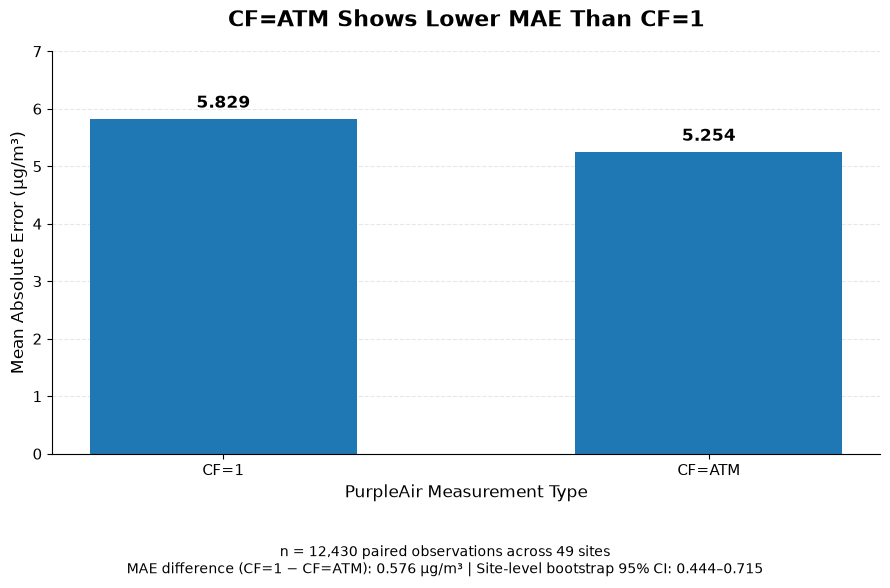

Figure saved to: reports/figures/dataset_a_mae_cf1_vs_cfatm.png


In [223]:


# Dataset A raw-measurement MAE
measurements = ["CF=1", "CF=ATM"]
mae_values = [5.829, 5.254]

# Create figure
fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    measurements,
    mae_values,
    width=0.55
)

# Title and labels
ax.set_title(
    "CF=ATM Shows Lower MAE Than CF=1",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_ylabel("Mean Absolute Error (µg/m³)", fontsize=12)
ax.set_xlabel("PurpleAir Measurement Type", fontsize=12)

ax.set_ylim(0, 7)
ax.tick_params(axis="both", labelsize=11)

# Add values above bars
for bar, value in zip(bars, mae_values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.12,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

# Add sample and uncertainty information
fig.text(
    0.5,
    0.035,
    "n = 12,430 paired observations across 49 sites"
    "\nMAE difference (CF=1 − CF=ATM): 0.576 µg/m³"
    " | Site-level bootstrap 95% CI: 0.444–0.715",
    ha="center",
    fontsize=10
)

# Clean presentation
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout(rect=[0, 0.13, 1, 1])

# Save high-resolution figure
figure_path = FIGURES_DIR / "dataset_a_mae_cf1_vs_cfatm.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", figure_path.resolve())

**Figure.** Mean absolute error (MAE) of PurpleAir CF=1 and CF=ATM measurements against reference monitors in Dataset A. CF=ATM had a lower MAE by 0.576 µg/m³ (site-level bootstrap 95% CI: 0.444–0.715; 12,430 paired observations across 49 sites). Lower MAE indicates closer agreement with reference measurements.


## Dataset A EDA Summary and Modeling Implications

### 1. Summary of Exploratory Findings

Dataset A contains 12,430 observations across 49 sites, 830 unique dates, and 9,707 distinct site-date combinations. The study period extends from September 30, 2017, through January 13, 2020. Observations are unevenly distributed across sites and time.

**Measurement distributions and agreement**

Reference-monitor PM2.5 concentrations and both raw PurpleAir measurement types are right-skewed. The PurpleAir measurements have higher upper-tail concentrations than the reference measurements.

Both raw PurpleAir outputs exhibit positive average measurement bias:

- CF=1: mean bias = 4.845 µg/m³; MAE = 5.829 µg/m³; RMSE = 8.807 µg/m³.
- CF=ATM: mean bias = 4.259 µg/m³; MAE = 5.254 µg/m³; RMSE = 7.461 µg/m³.

CF=ATM has lower aggregate MAE, RMSE, and mean absolute error across the observed concentration ranges. Its MAE advantage over CF=1 is approximately 0.576 µg/m³, with a site-level bootstrap 95% confidence interval of 0.444–0.715 µg/m³.

The Bland–Altman analysis also shows positive mean bias for both measurement types and relatively wide limits of agreement. The plots suggest increasing disagreement at higher measurement levels.

**Concentration-dependent error**

Measurement errors increase with reference PM2.5 concentration. Both measurement types show positive concentration-related error patterns, although the magnitude and variability differ across concentration ranges.

The quadratic concentration analysis provides evidence of a positive quadratic term for CF=1, while the corresponding CF=ATM quadratic term is not statistically distinguishable from zero at the 0.05 level. These results should be interpreted cautiously because observations are repeated within sites.

**Environmental relationships**

Relative humidity (RH) has the strongest observed environmental association with measurement error. After adjustment for reference concentration and site, the estimated error increases by approximately 1.617 µg/m³ per 10-percentage-point increase in RH for CF=1 and 1.515 µg/m³ for CF=ATM.

The positive RH association remains similar in sensitivity analyses excluding nonpositive reference measurements, accounting for nonlinear concentration effects, and controlling for reference-monitor method.

Temperature shows a negative association with measurement error in the correlation analysis, but its relationship is nonlinear. Dewpoint has a comparatively weak association with error and is correlated with temperature. RH is therefore the primary environmental predictor candidate, with temperature as a possible additional predictor and dewpoint as a lower-priority exploratory variable.

**Site and regional variability**

Measurement errors vary across sites and regions. The North region has the highest aggregate MAE among the reported regions, while Alaska has the lowest. Site-level comparisons also show substantial differences in error magnitude.

These descriptive differences may reflect site characteristics, concentration distributions, environmental conditions, and reference-monitor composition. They do not establish that a model will generalize to unseen sites.

**Temporal patterns**

Monthly MAE varies substantially over the study period. CF=ATM has lower or equal MAE than CF=1 in 28 of 29 observed months, with equal MAE in September 2017 based on one observation.

The broad monthly pattern remains similar when restricting the analysis to 18 sites with observations in at least 12 distinct months. However, the restricted analysis is not a fully balanced site-month panel because site participation and observation counts still vary over time.

These results do not establish seasonal effects or causal temporal changes in sensor performance.

### 2. Data-Quality and Analytical Decisions

The original observations are retained, with the following considerations carried forward:

- Retain all 44 nonpositive reference measurements in the original dataset and flag them for metric-specific sensitivity analyses.
- Preserve missing RH, temperature, and dewpoint values without arbitrary imputation.
- Do not automatically remove extreme PM2.5 concentrations or measurement errors.
- Avoid MAPE where reference values are zero or negative.
- Do not treat repeated observations within site-date combinations as independent.
- Use consistent eligible observations when comparing model performance.
- Perform imputation, scaling, and feature transformations using training data only.

### 3. Modeling Implications

The EDA supports the following candidate modeling approach:

- **Primary raw measurement baseline:** PM25cf1.
- **Alternative raw measurement baseline:** PM25cfatm.
- **Primary target:** Reference-monitor PM2.5 concentration (`PM25FM`).
- **Primary environmental predictor candidate:** Relative humidity (`RH`).
- **Additional predictor candidate:** Temperature (`TempC`).
- **Exploratory predictor:** Dewpoint, subject to its overlap with RH and temperature.

The initial modeling comparisons should include raw measurements, a linear calibration model, and a humidity-aware calibration model. Nonlinear concentration effects can be investigated if supported by validation results.

Model performance should be evaluated using MAE, RMSE, mean bias, and R², with particular attention to concentration-dependent error and agreement.

Validation partitions must account for repeated observations and match the intended generalization question. Grouping by site-date is necessary to prevent related observations from crossing partitions. A held-out-site evaluation should be considered when assessing generalization to unseen sites.

### 4. Limitations and Transition to Model Development

Dataset A provides 24-hour collocation evidence, but it does not independently establish calibration performance under hourly wildfire-smoke conditions. Dataset B must be evaluated separately to address the smoke-performance component of the research question.

The current findings are primarily descriptive and observational. They identify measurement patterns, potential predictors, and analytical constraints, but do not establish the performance of independently trained calibration models.

The next stage will use these EDA findings to develop and evaluate calibration models on appropriately held-out observations. Model performance under wildfire-smoke conditions will be assessed separately using Dataset B.

# Three Things the Dataset A Data Says
**Project:** Evaluating Low-Cost PM2.5 Sensors: Calibration Accuracy, Generalization, and Reliability  
**Dataset:** 24-hour PurpleAir/reference-monitor collocation data

## 1. CF=ATM has lower raw-measurement error than CF=1.

CF=ATM had a mean absolute error (MAE) of **5.254 µg/m³**, compared with **5.829 µg/m³** for CF=1. The difference was **0.576 µg/m³**, favoring CF=ATM, across 12,430 paired observations from 49 sites.

**Is the difference bigger than the noise?** A site-level bootstrap with 5,000 resamples gave a 95% confidence interval of **0.444 to 0.715 µg/m³** for the MAE difference. The interval excludes zero. Excluding the 44 nonpositive reference observations gave a similar difference of 0.578 µg/m³ (95% CI: 0.446–0.718).

**Could something else explain it?** The comparison was also examined across concentration groups, where CF=ATM had lower MAE in every group. However, the highest-concentration groups had very small sample sizes. Site-level uncertainty was considered, but this result does not establish that CF=ATM performs better at every individual site or at unseen sites.

**Interpretation:** In this dataset, CF=ATM agrees more closely with the reference measurements than CF=1, before fitting a new calibration model.

## 2. Higher relative humidity is associated with greater measurement error, even after adjusting for site and concentration.

After adjusting for reference PM2.5 concentration and site, each 10-percentage-point increase in relative humidity was associated with:

- **CF=1:** +1.607 µg/m³ signed error (95% CI: 1.365–1.849).
- **CF=ATM:** +1.521 µg/m³ signed error (95% CI: 1.287–1.756).

The complete-case analysis included 12,369 observations with positive reference concentrations and available RH measurements across 49 sites. Standard errors were clustered by site.

**Is the association robust?** It remained nearly unchanged after excluding nonpositive reference values, adding a quadratic concentration term, and adjusting for FEM/FRM method. In leave-one-site-out checks, all 49 estimated CF=1 RH coefficients remained positive, and their confidence intervals excluded zero.

**Could something else explain it?** Site fixed effects and concentration adjustment reduce two important alternative explanations. However, unmeasured weather, time, or other environmental conditions could still contribute. This is an observational association, not proof that humidity causes the error.

**Interpretation:** Relative humidity is a strong candidate predictor to investigate in the calibration models.

## 3. Signed measurement error is associated with reference PM2.5 concentration, with different evidence for curvature between the two raw outputs.

After accounting for site differences, both outputs had positive linear concentration terms:

- **CF=1:** linear coefficient +0.746 (95% CI: 0.583–0.910; p < 0.001).
- **CF=ATM:** linear coefficient +0.746 (95% CI: 0.561–0.930; p < 0.001).

The quadratic concentration term was positive and statistically significant for CF=1 (+0.0053; 95% CI: 0.0023–0.0082; p = 0.00048), but not for CF=ATM (−0.0040; 95% CI: −0.0092–0.0012; p = 0.129).

**Is the evidence sufficient?** The model used 12,369 positive-reference observations and accounted for site differences, with standard errors clustered by site. The quadratic result suggests additional curvature for CF=1, but we have not formally tested whether the two quadratic effects differ from each other.

**Could something else explain it?** Site differences were included in the model, but other conditions may still affect the relationship. These results concern signed error, not absolute error, and should not be interpreted as proof that every observation becomes less accurate as concentration increases.

**Interpretation:** Reference concentration should be considered when evaluating calibration performance, and the concentration-error relationship should be checked separately for each raw measurement output.

---

## A finding we did not promote

We observed positive simple RH-error slopes at 42 of 46 eligible sites, but four sites had negative slopes. These were unadjusted site-specific estimates. Therefore, we did not claim that the RH relationship is identical at every site. The overall adjusted association was robust to removing individual sites, but that does not establish identical site-specific effects.

## What this means for the project

Dataset A provides evidence that raw measurement error varies with humidity, concentration, and site, and that CF=ATM has lower aggregate MAE than CF=1 in this collocation dataset.

The next step is to fit and evaluate calibration models using the planned predictors, while respecting site-level dependence and held-out-site evaluation. Dataset B will separately test whether calibration performance holds under wildfire-smoke conditions.

**Data source:** `data/raw/24hr_collocation/Full24hrdataset.csv`  
**Reference paper:** Barkjohn, K. K., Gantt, B., & Clements, A. L. (2021). [Development and application of a United States-wide correction for PM2.5 data collected with the PurpleAir sensor](https://amt.copernicus.org/articles/14/4617/2021/). *Atmospheric Measurement Techniques*, 14, 4617–4637.

# Part 2 — Exploratory Data Analysis: Dataset B (Hourly Wildfire-Smoke)

## 1. Dataset Structure and Configuration Design

Dataset B contains hourly PurpleAir/reference-monitor observations collected during periods that include wildfire-smoke conditions. Unlike Dataset A, which contains 24-hour collocation measurements, this dataset provides hourly observations and supplied correction results under different withholding configurations.

The dataset contains six adjustment types (A–F) and two withholding approaches (LOBD and LOSO). Each underlying city–sensor–timestamp observation appears in all 12 configurations.

The original raw PurpleAir measurement (`PA`), reference measurement (`ref`), and relative humidity (`RH`) are consistent across configurations, while the supplied adjusted measurement (`adj`) varies.

These configuration records represent alternative correction and withholding results for the same underlying hourly observation. They must not be treated as independent measurements or randomly divided across training and testing partitions.

The detailed structural, missingness, and data-quality checks are documented in Notebook 01. This section focuses on the measurement distributions, correction comparisons, and performance patterns relevant to the wildfire-smoke evaluation.

### Withholding Configuration and Structural Missingness

In [224]:
# Verify withholding labels and structural missingness
withholding_check = (
    df_smoke.groupby("wholdtype")
    .agg(
        rows=("hr", "size"),
        unique_cities=("city", "nunique"),
        unique_sensors=("id", "nunique"),
        week_missing=("week", lambda x: x.isna().sum()),
        week_nonmissing=("week", lambda x: x.notna().sum()),
        state_missing=("State", lambda x: x.isna().sum()),
        state_nonmissing=("State", lambda x: x.notna().sum())
    )
)

display(withholding_check)

,rows,unique_cities,unique_sensors,week_missing,week_nonmissing,state_missing,state_nonmissing
wholdtype,,,,,,,
LOBD,756888,27,27,0,756888,756888,0
LOSO,756888,27,27,756888,0,0,756888


In [225]:
# Inspect State values in the LOSO configuration
loso_state_summary = (
    df_smoke.loc[df_smoke["wholdtype"] == "LOSO"]
    .groupby("State", dropna=False)
    .agg(
        rows=("hr", "size"),
        unique_cities=("city", "nunique"),
        unique_sensors=("id", "nunique")
    )
    .sort_values("rows", ascending=False)
)

display(loso_state_summary)

,rows,unique_cities,unique_sensors
State,,,
PALinn2,117042,1,1
Atascadero,101160,1,1
PAMarysville 7th,63090,1,1
PASCG Air & Water Quality_EPA Air Sensor,54870,1,1
LTPP_CO,52968,1,1
PAAppleton,52332,1,1
PAKNI_E2,49686,1,1
LTPP_OK,49044,1,1
LTPP_GA,41208,1,1


In [226]:
# Inspect the relationship between State, city, and sensor ID
state_site_mapping = (
    df_smoke.loc[df_smoke["wholdtype"] == "LOSO"]
    .groupby(["State", "city", "id"], dropna=False)
    .size()
    .reset_index(name="rows")
    .sort_values("State")
)

display(state_site_mapping)

,State,city,id,rows
0,Alder WF,Pinehurst_S,Alder WF,942
1,Alpine Burns,Oakley_S,Alpine Burns,288
2,Atascadero,Atascadero,Atascadero,101160
3,Bend,Bend_S,Bend,10548
4,Boise,Boise_S,Boise,10518
5,El Portal,El Portal_S,El Portal,7674
6,Forks of Salmon,Forks of S._S,Forks of Salmon,7194
7,Hoopa,Hoopa_S,Hoopa,9792
8,Keeler,Keeler_S,Keeler,11256
9,LTPP_AZ,Phoenix,LTPP_AZ,21912


In [227]:
# Inspect LOBD observation counts by calendar year and week
lobd_week_coverage = (
    df_smoke.loc[df_smoke["wholdtype"] == "LOBD"]
    .assign(
        year=pd.to_datetime(df_smoke.loc[
            df_smoke["wholdtype"] == "LOBD", "hr"
        ]).dt.year
    )
    .groupby(["year", "week"])
    .size()
    .unstack(fill_value=0)
)

display(lobd_week_coverage)

week,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,44.0,45.0,46.0,47.0,48.0,49.0,50.0,51.0,52.0,53.0
year,,,,,,,,,,,,,,,,,,,,,
2018,0,996,984,966,978,996,996,984,966,996,...,2418,2994,2988,2988,3000,2994,2982,2988,2496,432
2019,3378,3918,3936,3864,3816,3912,3882,3936,3828,3906,...,9876,9834,8322,8634,8142,8058,8556,8598,2364,0
2020,5550,8550,8694,7998,7104,7032,7260,7710,7500,7434,...,0,0,0,0,0,0,0,0,0,0


### Underlying Observation Key and Raw-Measurement Consistency

In [228]:
# Validate the underlying hourly observation key

observation_key = ["city", "id", "hr"]

print("Total configuration rows:", len(df_smoke))

print(
    "Unique underlying observations:",
    df_smoke[observation_key].drop_duplicates().shape[0]
)

configuration_counts = (
    df_smoke
    .groupby(observation_key, dropna=False)
    .size()
)

print("\nConfiguration records per observation:")
display(configuration_counts.value_counts().sort_index())

print("\nObservations with other than 12 configurations:")
print((configuration_counts != 12).sum())

print("\nDuplicate configuration combinations:")
print(
    df_smoke.duplicated(
        observation_key + ["adjtype", "wholdtype"]
    ).sum()
)

print("\nUnique adjustment types:")
print(sorted(df_smoke["adjtype"].dropna().unique()))

print("\nUnique withholding types:")
print(sorted(df_smoke["wholdtype"].dropna().unique()))

Total configuration rows: 1513776
Unique underlying observations: 126148

Configuration records per observation:


12    126148
Name: count, dtype: int64


Observations with other than 12 configurations:
0

Duplicate configuration combinations:
0

Unique adjustment types:
['A', 'B', 'C', 'D', 'E', 'F']

Unique withholding types:
['LOBD', 'LOSO']


In [229]:
# Verify raw measurements are consistent across configurations

raw_columns = ["PA", "ref", "RH"]

raw_consistency = (
    df_smoke
    .groupby(observation_key)[raw_columns]
    .nunique(dropna=False)
)

print("Observations with inconsistent raw measurements:")
display(
    (raw_consistency > 1)
    .sum()
    .rename("Inconsistent_Observations")
    .to_frame()
)

# Create one record per underlying hourly observation.
# Retain LOBD records explicitly so the selected withholding
# configuration is deterministic.

df_smoke_obs = (
    df_smoke.loc[df_smoke["wholdtype"] == "LOBD"]
    .drop_duplicates(subset=observation_key)
    .copy()
)

print("\nObservation-level dataset shape:", df_smoke_obs.shape)

print(
    "Unique observation keys:",
    df_smoke_obs[observation_key].drop_duplicates().shape[0]
)

print(
    "Retained withholding approach:",
    df_smoke_obs["wholdtype"].unique()
)

Observations with inconsistent raw measurements:


,Inconsistent_Observations
PA,0
ref,0
RH,0



Observation-level dataset shape: (126148, 13)
Unique observation keys: 126148
Retained withholding approach: <StringArray>
['LOBD']
Length: 1, dtype: str


### Raw Measurement Distributions

In [230]:
# Inspect raw PurpleAir and reference PM2.5 distributions
# Use one row per underlying hourly observation.

smoke_distribution = df_smoke_obs[["PA", "ref"]].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
).T

smoke_distribution["Skewness"] = (
    df_smoke_obs[["PA", "ref"]].skew()
)

smoke_distribution["Nonpositive_Count"] = (
    df_smoke_obs[["PA", "ref"]].le(0).sum()
)

smoke_distribution["Missing_Count"] = (
    df_smoke_obs[["PA", "ref"]].isna().sum()
)

display(smoke_distribution.round(3))

,count,mean,std,min,25%,50%,75%,90%,95%,99%,99.9%,max,Skewness,Nonpositive_Count,Missing_Count
PA,126148.0,20.915,67.155,0.0,3.357,7.671,16.573,32.577,55.783,342.108,878.637,1561.376,9.560,58,0
ref,126148.0,13.725,47.522,-9.8,4.200,6.900,11.000,18.265,29.000,180.000,709.000,1506.000,14.236,4916,0


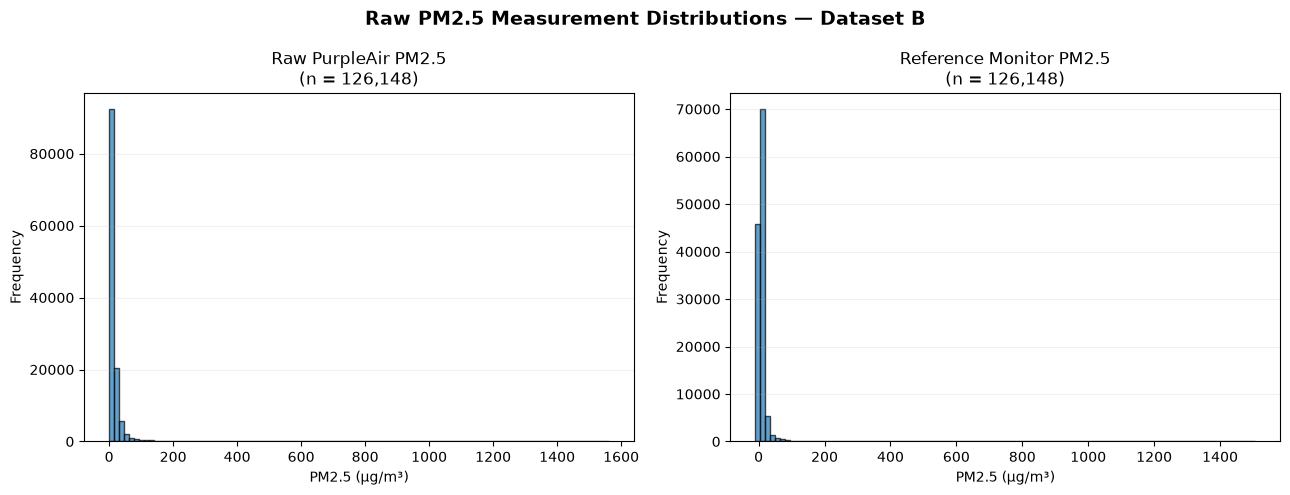

Figure saved to: reports/figures/dataset_b_raw_distributions.png


In [231]:
# Plot raw PurpleAir and reference PM2.5 distributions
# Use one row per underlying hourly observation.

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, column, title in [
    (axes[0], "PA", "Raw PurpleAir PM2.5"),
    (axes[1], "ref", "Reference Monitor PM2.5")
]:
    values = df_smoke_obs[column].dropna()

    ax.hist(
        values,
        bins=100,
        edgecolor="black",
        alpha=0.7
    )

    ax.set_title(f"{title}\n(n = {len(values):,})")
    ax.set_xlabel("PM2.5 (µg/m³)")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.2)

plt.suptitle(
    "Raw PM2.5 Measurement Distributions — Dataset B",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

figure_path = FIGURES_DIR / "dataset_b_raw_distributions.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure_path.resolve())

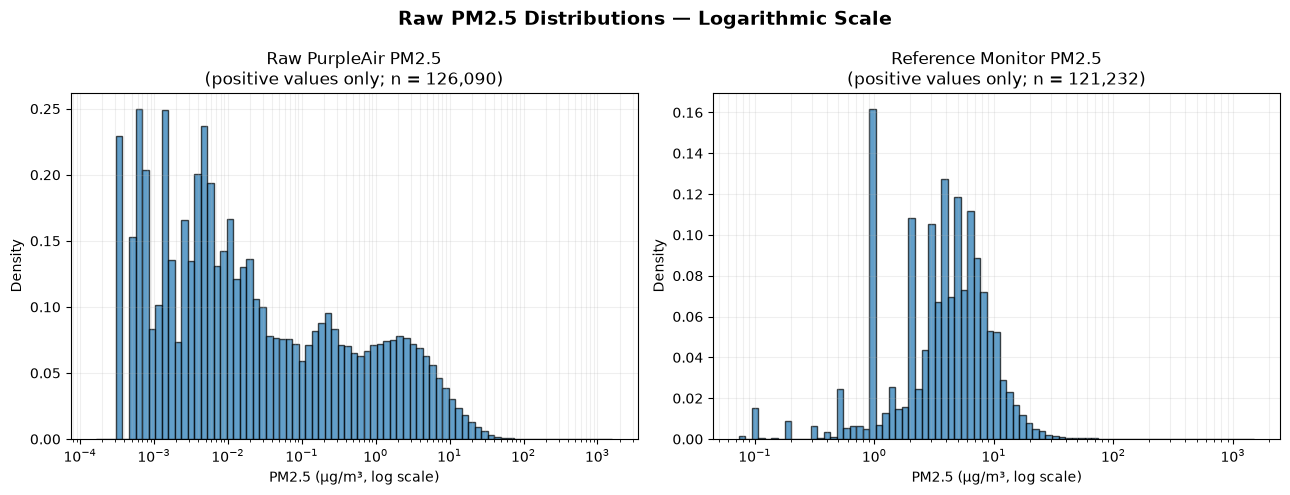

Figure saved to: reports/figures/dataset_b_raw_distributions_log_scale.png


In [232]:
# Plot raw distributions using logarithmically spaced bins.
# Nonpositive values are excluded only for this visualization.

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, column, title in [
    (axes[0], "PA", "Raw PurpleAir PM2.5"),
    (axes[1], "ref", "Reference Monitor PM2.5")
]:
    values = df_smoke_obs.loc[
        df_smoke_obs[column] > 0, column
    ].dropna()

    log_bins = np.logspace(
        np.log10(values.min()),
        np.log10(values.max()),
        80
    )

    ax.hist(
        values,
        bins=log_bins,
        density=True,
        edgecolor="black",
        alpha=0.7
    )

    ax.set_xscale("log")
    ax.set_title(f"{title}\n(positive values only; n = {len(values):,})")
    ax.set_xlabel("PM2.5 (µg/m³, log scale)")
    ax.set_ylabel("Density")
    ax.grid(True, alpha=0.2, which="both")

plt.suptitle(
    "Raw PM2.5 Distributions — Logarithmic Scale",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

figure_path = FIGURES_DIR / "dataset_b_raw_distributions_log_scale.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure_path.resolve())

### Raw PurpleAir vs. Reference Monitor

In [233]:
# Raw PurpleAir vs. reference measurement performance

from scipy.stats import spearmanr

raw_pa = df_smoke_obs["PA"]
raw_ref = df_smoke_obs["ref"]

raw_error = raw_pa - raw_ref

raw_metrics = pd.DataFrame({
    "Metric": [
        "Observations",
        "Mean Bias",
        "MAE",
        "RMSE",
        "Median Absolute Error",
        "Spearman Correlation"
    ],
    "Value": [
        len(df_smoke_obs),
        raw_error.mean(),
        raw_error.abs().mean(),
        np.sqrt((raw_error ** 2).mean()),
        raw_error.abs().median(),
        spearmanr(raw_pa, raw_ref).statistic
    ]
})

display(raw_metrics.round(4))

print("\nReference values:")
print("Positive:", (raw_ref > 0).sum())
print("Zero:", (raw_ref == 0).sum())
print("Negative:", (raw_ref < 0).sum())

,Metric,Value
0,Observations,126148.0000
1,Mean Bias,7.1907
2,MAE,9.0343
3,RMSE,26.2232
4,Median Absolute Error,2.9820
5,Spearman Correlation,0.8236



Reference values:
Positive: 121232
Zero: 2463
Negative: 2453


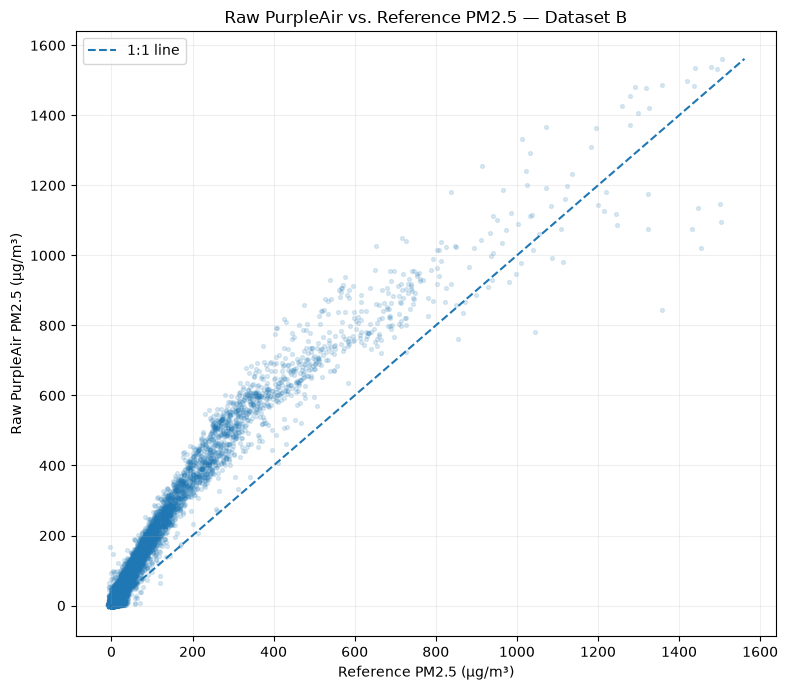

Figure saved to: reports/figures/dataset_b_raw_pa_vs_reference.png


In [234]:
# Scatterplot of raw PurpleAir vs. reference measurements

fig, ax = plt.subplots(figsize=(8, 7))

ax.scatter(
    df_smoke_obs["ref"],
    df_smoke_obs["PA"],
    alpha=0.15,
    s=8
)

# 1:1 reference line
plot_min = min(
    df_smoke_obs["ref"].min(),
    df_smoke_obs["PA"].min()
)
plot_max = max(
    df_smoke_obs["ref"].max(),
    df_smoke_obs["PA"].max()
)

ax.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    linestyle="--",
    label="1:1 line"
)

ax.set_xlabel("Reference PM2.5 (µg/m³)")
ax.set_ylabel("Raw PurpleAir PM2.5 (µg/m³)")
ax.set_title("Raw PurpleAir vs. Reference PM2.5 — Dataset B")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

figure_path = FIGURES_DIR / "dataset_b_raw_pa_vs_reference.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure_path.resolve())

### Measurement Error Across PM2.5 Concentrations

In [235]:
# Calculate raw measurement error across reference concentration ranges

smoke_error_data = df_smoke_obs[
    ["PA", "ref"]
].copy()

smoke_error_data["Error"] = (
    smoke_error_data["PA"] - smoke_error_data["ref"]
)

smoke_error_data["Absolute_Error"] = (
    smoke_error_data["Error"].abs()
)

# Create concentration groups
smoke_error_data["Concentration_Group"] = pd.cut(
    smoke_error_data["ref"],
    bins=[0, 5, 10, 15, 20, 30, 50, 100, 200, 500, np.inf],
    labels=[
        "0–5", "5–10", "10–15", "15–20", "20–30",
        "30–50", "50–100", "100–200", "200–500", "≥500"
    ],
    right=False
).astype("object")

# Include zero and negative reference values
smoke_error_data.loc[
    smoke_error_data["ref"] <= 0,
    "Concentration_Group"
] = "Nonpositive"

smoke_concentration_summary = (
    smoke_error_data
    .groupby("Concentration_Group", observed=False)
    .agg(
        Observations=("Error", "size"),
        Mean_Reference=("ref", "mean"),
        Mean_Bias=("Error", "mean"),
        MAE=("Absolute_Error", "mean"),
        RMSE=("Error", lambda x: np.sqrt((x ** 2).mean()))
    )
)

display(smoke_concentration_summary.round(3))

,Observations,Mean_Reference,Mean_Bias,MAE,RMSE
Concentration_Group,,,,,
0–5,33439,3.187,0.230,2.247,3.442
100–200,844,141.078,129.858,130.084,136.316
10–15,18906,11.861,6.008,7.507,9.588
15–20,7394,16.907,10.249,12.004,14.498
200–500,894,308.695,205.349,205.370,212.678
20–30,5022,23.693,16.774,18.403,21.607
30–50,2350,37.424,33.063,34.086,38.114
50–100,1744,68.047,67.411,67.904,72.854
5–10,50368,6.981,1.516,3.578,5.193


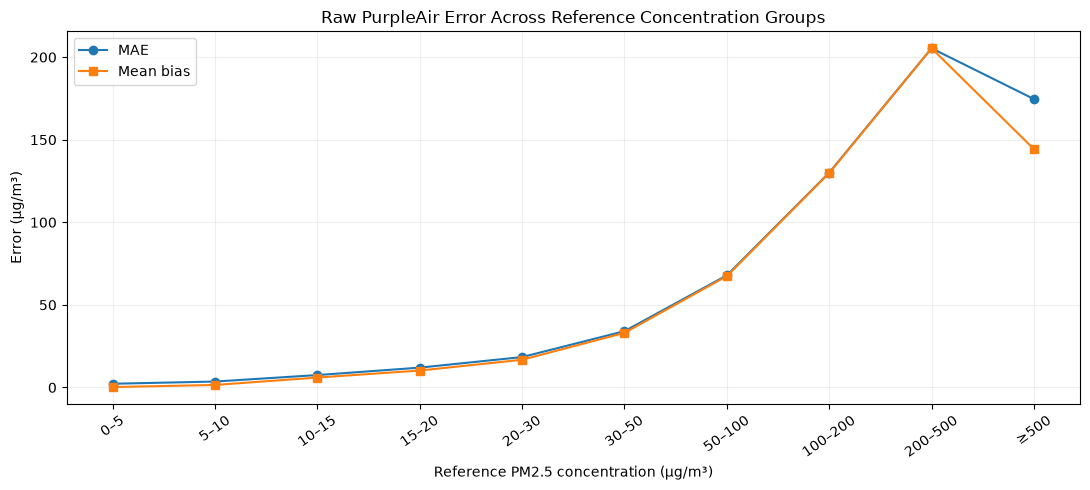

Figure saved to: reports/figures/dataset_b_raw_error_by_concentration.png


In [236]:
# Plot raw measurement bias and MAE across reference concentration groups

plot_data = smoke_concentration_summary.drop(
    index="Nonpositive"
).copy()

# Restore numerical concentration order
bin_order = [
    "0–5", "5–10", "10–15", "15–20", "20–30",
    "30–50", "50–100", "100–200", "200–500", "≥500"
]

plot_data = plot_data.reindex(bin_order)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    bin_order,
    plot_data["MAE"],
    marker="o",
    label="MAE"
)

ax.plot(
    bin_order,
    plot_data["Mean_Bias"],
    marker="s",
    label="Mean bias"
)

ax.set_xlabel("Reference PM2.5 concentration (µg/m³)")
ax.set_ylabel("Error (µg/m³)")
ax.set_title("Raw PurpleAir Error Across Reference Concentration Groups")
ax.legend()
ax.grid(alpha=0.2)
plt.xticks(rotation=35)

plt.tight_layout()

figure_path = FIGURES_DIR / "dataset_b_raw_error_by_concentration.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure_path.resolve())

### Adjustment and Withholding Configuration Comparisons

In [237]:
# Inspect adjustment and withholding configuration combinations

configuration_summary = (
    df_smoke
    .groupby(["adjtype", "wholdtype"], observed=True)
    .agg(
        Rows=("adj", "size"),
        Unique_Observations=(
            "hr",
            "count"
        ),
        Mean_Adjusted=("adj", "mean"),
        Mean_RH=("RH", "mean")
    )
    .reset_index()
)

display(configuration_summary.round(3))

print("\nMissing adjusted values:", df_smoke["adj"].isna().sum())
print("Missing adjustment types:", df_smoke["adjtype"].isna().sum())
print("Missing withholding types:", df_smoke["wholdtype"].isna().sum())

,adjtype,wholdtype,Rows,Unique_Observations,Mean_Adjusted,Mean_RH
0,A,LOBD,126148,126148,12.522,48.584
1,A,LOSO,126148,126148,12.522,48.584
2,B,LOBD,126148,126148,13.737,48.584
3,B,LOSO,126148,126148,13.714,48.584
4,C,LOBD,126148,126148,13.769,48.584
5,C,LOSO,126148,126148,13.797,48.584
6,D,LOBD,126148,126148,13.739,48.584
7,D,LOSO,126148,126148,13.707,48.584
8,E,LOBD,126148,126148,13.717,48.584
9,E,LOSO,126148,126148,13.717,48.584



Missing adjusted values: 0
Missing adjustment types: 0
Missing withholding types: 0


In [238]:
# Evaluate adjusted measurements against reference values
# using all 12 configurations

df_smoke["Adjusted_Error"] = df_smoke["adj"] - df_smoke["ref"]
df_smoke["Absolute_Adjusted_Error"] = df_smoke["Adjusted_Error"].abs()

configuration_performance = (
    df_smoke
    .groupby(["adjtype", "wholdtype"], observed=True)
    .agg(
        Observations=("Adjusted_Error", "size"),
        Mean_Bias=("Adjusted_Error", "mean"),
        MAE=("Absolute_Adjusted_Error", "mean"),
        RMSE=("Adjusted_Error", lambda x: np.sqrt((x ** 2).mean())),
        Median_Absolute_Error=("Absolute_Adjusted_Error", "median")
    )
    .reset_index()
)

# Add raw PurpleAir baseline for comparison
raw_baseline = pd.DataFrame([{
    "adjtype": "Raw PA",
    "wholdtype": "Baseline",
    "Observations": len(df_smoke_obs),
    "Mean_Bias": (df_smoke_obs["PA"] - df_smoke_obs["ref"]).mean(),
    "MAE": (df_smoke_obs["PA"] - df_smoke_obs["ref"]).abs().mean(),
    "RMSE": np.sqrt(
        ((df_smoke_obs["PA"] - df_smoke_obs["ref"]) ** 2).mean()
    ),
    "Median_Absolute_Error": (
        df_smoke_obs["PA"] - df_smoke_obs["ref"]
    ).abs().median()
}])

configuration_performance = pd.concat(
    [raw_baseline, configuration_performance],
    ignore_index=True
)

display(configuration_performance.round(3))

,adjtype,wholdtype,Observations,Mean_Bias,MAE,RMSE,Median_Absolute_Error
0,Raw PA,Baseline,126148,7.191,9.034,26.223,2.982
1,A,LOBD,126148,-1.203,3.604,16.874,1.893
2,A,LOSO,126148,-1.203,3.604,16.874,1.893
3,B,LOBD,126148,0.012,2.990,10.570,1.516
4,B,LOSO,126148,-0.011,3.020,10.028,1.541
5,C,LOBD,126148,0.044,3.097,12.933,1.558
6,C,LOSO,126148,0.072,3.140,12.412,1.586
7,D,LOBD,126148,0.014,2.928,10.563,1.473
8,D,LOSO,126148,-0.018,2.966,10.021,1.506
9,E,LOBD,126148,-0.008,2.995,10.353,1.568


In [239]:
# Calculate error reduction relative to raw PurpleAir baseline

raw_mae = raw_metrics.loc[
    raw_metrics["Metric"] == "MAE", "Value"
].iloc[0]

raw_rmse = raw_metrics.loc[
    raw_metrics["Metric"] == "RMSE", "Value"
].iloc[0]

adjusted_comparison = configuration_performance.copy()

adjusted_comparison["MAE_Reduction_Percent"] = (
    (raw_mae - adjusted_comparison["MAE"]) / raw_mae
) * 100

adjusted_comparison["RMSE_Reduction_Percent"] = (
    (raw_rmse - adjusted_comparison["RMSE"]) / raw_rmse
) * 100

display(
    adjusted_comparison[
        [
            "adjtype",
            "wholdtype",
            "MAE",
            "RMSE",
            "MAE_Reduction_Percent",
            "RMSE_Reduction_Percent"
        ]
    ].round(2)
)

,adjtype,wholdtype,MAE,RMSE,MAE_Reduction_Percent,RMSE_Reduction_Percent
0,Raw PA,Baseline,9.03,26.22,0.00,0.00
1,A,LOBD,3.60,16.87,60.11,35.65
2,A,LOSO,3.60,16.87,60.11,35.65
3,B,LOBD,2.99,10.57,66.91,59.69
4,B,LOSO,3.02,10.03,66.57,61.76
5,C,LOBD,3.10,12.93,65.71,50.68
6,C,LOSO,3.14,12.41,65.25,52.67
7,D,LOBD,2.93,10.56,67.59,59.72
8,D,LOSO,2.97,10.02,67.17,61.79
9,E,LOBD,3.00,10.35,66.85,60.52


In [240]:
# Compare LOBD and LOSO performance within each adjustment type

withholding_comparison = (
    configuration_performance[
        configuration_performance["adjtype"] != "Raw PA"
    ]
    .pivot(
        index="adjtype",
        columns="wholdtype",
        values=["MAE", "RMSE", "Mean_Bias"]
    )
)

withholding_comparison.columns = [
    f"{metric}_{method}"
    for metric, method in withholding_comparison.columns
]

withholding_comparison["LOSO_minus_LOBD_MAE"] = (
    withholding_comparison["MAE_LOSO"]
    - withholding_comparison["MAE_LOBD"]
)

withholding_comparison["LOSO_minus_LOBD_RMSE"] = (
    withholding_comparison["RMSE_LOSO"]
    - withholding_comparison["RMSE_LOBD"]
)

display(withholding_comparison.round(4))

,MAE_LOBD,MAE_LOSO,RMSE_LOBD,RMSE_LOSO,Mean_Bias_LOBD,Mean_Bias_LOSO,LOSO_minus_LOBD_MAE,LOSO_minus_LOBD_RMSE
adjtype,,,,,,,,
A,3.6037,3.6037,16.8738,16.8738,-1.2029,-1.2029,0.0000,0.0000
B,2.9898,3.0199,10.5699,10.0279,0.0122,-0.0109,0.0301,-0.5421
C,3.0975,3.1398,12.9326,12.4117,0.0445,0.0720,0.0423,-0.5209
D,2.9282,2.9661,10.5632,10.0212,0.0144,-0.0175,0.0379,-0.5420
E,2.9950,3.0464,10.3529,9.8845,-0.0079,-0.0080,0.0513,-0.4685
F,5.5149,5.5728,17.1028,17.2406,2.2169,2.2382,0.0579,0.1378


In [241]:
# Compare adjusted measurement performance across reference concentration groups

smoke_config_data = df_smoke[
    ["ref", "adj", "adjtype", "wholdtype"]
].copy()

smoke_config_data["Adjusted_Error"] = (
    smoke_config_data["adj"] - smoke_config_data["ref"]
)

smoke_config_data["Absolute_Error"] = (
    smoke_config_data["Adjusted_Error"].abs()
)

# Use the same concentration groups as the raw PA analysis
smoke_config_data["Concentration_Group"] = pd.cut(
    smoke_config_data["ref"],
    bins=[0, 5, 10, 15, 20, 30, 50, 100, 200, 500, np.inf],
    labels=[
        "0–5", "5–10", "10–15", "15–20", "20–30",
        "30–50", "50–100", "100–200", "200–500", "≥500"
    ],
    right=False
).astype("object")

smoke_config_data.loc[
    smoke_config_data["ref"] <= 0,
    "Concentration_Group"
] = "Nonpositive"

concentration_config_performance = (
    smoke_config_data
    .groupby(
        ["Concentration_Group", "adjtype", "wholdtype"],
        observed=True
    )
    .agg(
        Observations=("Adjusted_Error", "size"),
        Mean_Bias=("Adjusted_Error", "mean"),
        MAE=("Absolute_Error", "mean"),
        RMSE=(
            "Adjusted_Error",
            lambda x: np.sqrt((x ** 2).mean())
        )
    )
    .reset_index()
)

display(
    concentration_config_performance.round(3)
)

,Concentration_Group,adjtype,wholdtype,Observations,Mean_Bias,MAE,RMSE
0,0–5,A,LOBD,33439,0.219,1.742,2.307
1,0–5,A,LOSO,33439,0.219,1.742,2.307
2,0–5,B,LOBD,33439,1.608,1.679,2.309
3,0–5,B,LOSO,33439,1.644,1.722,2.367
4,0–5,C,LOBD,33439,1.854,1.881,2.442
...,...,...,...,...,...,...,...
127,≥500,D,LOSO,271,-48.050,131.485,174.994
128,≥500,E,LOBD,271,-39.683,130.614,182.556
129,≥500,E,LOSO,271,-44.797,123.125,166.857
130,≥500,F,LOBD,271,-66.410,120.923,187.242


In [242]:
# Compact MAE comparison by concentration and adjustment type

concentration_mae_comparison = (
    concentration_config_performance
    .pivot_table(
        index="Concentration_Group",
        columns="adjtype",
        values="MAE",
        aggfunc="mean"
    )
)

bin_order = [
    "Nonpositive", "0–5", "5–10", "10–15", "15–20",
    "20–30", "30–50", "50–100", "100–200", "200–500", "≥500"
]

concentration_mae_comparison = (
    concentration_mae_comparison.reindex(bin_order)
)

display(concentration_mae_comparison.round(3))

adjtype,A,B,C,D,E,F
Concentration_Group,,,,,,
Nonpositive,4.259,5.938,6.221,5.885,5.681,3.534
0–5,1.742,1.700,1.919,1.746,1.858,2.005
5–10,2.031,1.433,1.335,1.325,1.426,2.590
10–15,2.839,2.563,2.500,2.466,2.489,3.826
15–20,3.923,3.798,3.884,3.753,3.733,5.947
20–30,5.216,5.256,5.527,5.185,5.121,9.678
30–50,7.202,6.900,7.368,6.708,6.949,20.836
50–100,10.678,9.381,9.863,9.248,9.912,45.349
100–200,14.530,17.309,17.286,17.239,18.827,78.225


In [243]:
# Compare adjusted MAE with raw PA MAE by concentration group

raw_mae_by_group = (
    smoke_concentration_summary["MAE"]
    .rename("Raw_PA_MAE")
)

adjustment_vs_raw = concentration_mae_comparison.join(
    raw_mae_by_group
)

for adjustment in ["A", "B", "C", "D", "E", "F"]:
    adjustment_vs_raw[f"{adjustment}_MAE_Reduction_Percent"] = (
        (adjustment_vs_raw["Raw_PA_MAE"] - adjustment_vs_raw[adjustment])
        / adjustment_vs_raw["Raw_PA_MAE"]
    ) * 100

display(adjustment_vs_raw.round(2))

,A,B,C,D,E,F,Raw_PA_MAE,A_MAE_Reduction_Percent,B_MAE_Reduction_Percent,C_MAE_Reduction_Percent,D_MAE_Reduction_Percent,E_MAE_Reduction_Percent,F_MAE_Reduction_Percent
Concentration_Group,,,,,,,,,,,,,
Nonpositive,4.26,5.94,6.22,5.88,5.68,3.53,4.46,4.49,-33.16,-39.51,-31.97,-27.39,20.74
0–5,1.74,1.70,1.92,1.75,1.86,2.00,2.25,22.46,24.33,14.62,22.29,17.31,10.79
5–10,2.03,1.43,1.34,1.33,1.43,2.59,3.58,43.25,59.94,62.68,62.97,60.15,27.61
10–15,2.84,2.56,2.50,2.47,2.49,3.83,7.51,62.18,65.86,66.70,67.15,66.84,49.03
15–20,3.92,3.80,3.88,3.75,3.73,5.95,12.00,67.32,68.36,67.64,68.74,68.91,50.46
20–30,5.22,5.26,5.53,5.19,5.12,9.68,18.40,71.65,71.44,69.97,71.82,72.17,47.41
30–50,7.20,6.90,7.37,6.71,6.95,20.84,34.09,78.87,79.76,78.38,80.32,79.61,38.87
50–100,10.68,9.38,9.86,9.25,9.91,45.35,67.90,84.28,86.19,85.48,86.38,85.40,33.22
100–200,14.53,17.31,17.29,17.24,18.83,78.23,130.08,88.83,86.69,86.71,86.75,85.53,39.87


In [244]:
# Examine adjusted MAE across relative humidity ranges

smoke_rh_data = df_smoke[
    ["RH", "ref", "adj", "adjtype", "wholdtype"]
].copy()

smoke_rh_data["Absolute_Error"] = (
    smoke_rh_data["adj"] - smoke_rh_data["ref"]
).abs()

smoke_rh_data["RH_Group"] = pd.cut(
    smoke_rh_data["RH"],
    bins=[-float("inf"), 30, 40, 50, 60, 70, 80, float("inf")],
    labels=["<30", "30–40", "40–50", "50–60", "60–70", "70–80", "≥80"],
    right=False
)

rh_error_summary = (
    smoke_rh_data
    .groupby(
        ["RH_Group", "adjtype", "wholdtype"],
        observed=True
    )
    .agg(
        Observations=("Absolute_Error", "size"),
        MAE=("Absolute_Error", "mean")
    )
    .reset_index()
)

display(rh_error_summary.round(3))

,RH_Group,adjtype,wholdtype,Observations,MAE
0,<30,A,LOBD,23224,3.665
1,<30,A,LOSO,23224,3.665
2,<30,B,LOBD,23224,3.494
3,<30,B,LOSO,23224,3.502
4,<30,C,LOBD,23224,3.572
...,...,...,...,...,...
79,≥80,D,LOSO,834,1.875
80,≥80,E,LOBD,834,1.708
81,≥80,E,LOSO,834,1.777
82,≥80,F,LOBD,834,1.972


In [245]:
# Compare raw and adjusted MAE across relative humidity groups

raw_rh_data = df_smoke_obs[["RH", "PA", "ref"]].copy()

raw_rh_data["Absolute_Error"] = (
    raw_rh_data["PA"] - raw_rh_data["ref"]
).abs()

raw_rh_data["RH_Group"] = pd.cut(
    raw_rh_data["RH"],
    bins=[-float("inf"), 30, 40, 50, 60, 70, 80, float("inf")],
    labels=["<30", "30–40", "40–50", "50–60", "60–70", "70–80", "≥80"],
    right=False
)

raw_rh_mae = (
    raw_rh_data
    .groupby("RH_Group", observed=True)
    ["Absolute_Error"]
    .mean()
    .rename("Raw_PA_MAE")
)

adjusted_rh_mae = (
    rh_error_summary
    .groupby(["RH_Group", "adjtype"], observed=True)["MAE"]
    .mean()
    .unstack("adjtype")
)

rh_mae_comparison = adjusted_rh_mae.join(raw_rh_mae)

for adjustment in ["A", "B", "C", "D", "E", "F"]:
    rh_mae_comparison[f"{adjustment}_Reduction_Percent"] = (
        (rh_mae_comparison["Raw_PA_MAE"] - rh_mae_comparison[adjustment])
        / rh_mae_comparison["Raw_PA_MAE"]
    ) * 100

display(rh_mae_comparison.round(3))

,A,B,C,D,E,F,Raw_PA_MAE,A_Reduction_Percent,B_Reduction_Percent,C_Reduction_Percent,D_Reduction_Percent,E_Reduction_Percent,F_Reduction_Percent
RH_Group,,,,,,,,,,,,,
<30,3.665,3.498,3.588,3.508,3.758,9.465,11.889,69.171,70.578,69.825,70.494,68.391,20.389
30–40,3.952,3.360,3.632,3.335,3.295,7.610,10.556,62.559,68.174,65.593,68.407,68.786,27.908
40–50,4.398,3.346,3.560,3.339,3.297,5.422,8.436,47.860,60.332,57.800,60.419,60.922,35.726
50–60,3.459,2.661,2.724,2.667,2.648,4.056,7.588,54.420,64.937,64.103,64.852,65.107,46.549
60–70,2.875,2.513,2.551,2.415,2.507,3.322,7.696,62.641,67.343,66.848,68.624,67.418,56.830
70–80,3.436,2.716,2.745,2.446,2.662,3.427,8.425,59.218,67.755,67.422,70.967,68.399,59.325
≥80,2.583,2.420,2.536,1.832,1.743,1.979,3.890,33.600,37.781,34.817,52.900,55.204,49.132


## 2. Temporal Coverage and Missingness

In [246]:
# Examine temporal coverage of underlying hourly observations

smoke_time_data = df_smoke_obs.copy()

smoke_time_data["hr"] = pd.to_datetime(
    smoke_time_data["hr"],
    errors="coerce"
)

smoke_time_data["Date"] = smoke_time_data["hr"].dt.date
smoke_time_data["Year_Month"] = (
    smoke_time_data["hr"].dt.to_period("M").astype(str)
)

print("Date range:")
print(smoke_time_data["hr"].min(), "to", smoke_time_data["hr"].max())

print("\nUnderlying observations:", len(smoke_time_data))
print("Unique cities:", smoke_time_data["city"].nunique())
print("Unique sensors:", smoke_time_data["id"].nunique())
print(
    "Unique city-sensor groups:",
    smoke_time_data[["city", "id"]].drop_duplicates().shape[0]
)
print("Unique dates:", smoke_time_data["Date"].nunique())

print("\nMissing values:")
display(
    smoke_time_data[
        ["hr", "city", "id", "RH", "PA", "ref", "State", "week"]
    ].isna().sum().to_frame("Missing_Count")
)

print("\nObservations by month:")
display(
    smoke_time_data.groupby("Year_Month", observed=True)
    .size()
    .rename("Observations")
    .to_frame()
)

Date range:
2018-01-01 00:00:00 to 2020-10-20 11:00:00

Underlying observations: 126148
Unique cities: 27
Unique sensors: 27
Unique city-sensor groups: 27
Unique dates: 1024

Missing values:


,Missing_Count
hr,0
city,0
id,0
RH,0
PA,0
ref,0
State,126148
week,0



Observations by month:


,Observations
Year_Month,
2018-01,725
2018-02,656
2018-03,712
2018-04,713
2018-05,1375
2018-06,1374
2018-07,1453
2018-08,1750
2018-09,1436


The missingness shown above is calculated on `df_smoke_obs`, the observation-level dataset created by retaining one configuration record per underlying city–sensor–hour. Because the retained records are LOBD configurations, `State` appears entirely missing and `week` appears complete in this deduplicated dataset.

In the full configuration-level dataset, `State` is populated for LOSO records and missing for LOBD records, while `week` is populated for LOBD records and missing for LOSO records. This is structural missingness associated with the withholding approach, not general loss of measurement data. The `State` values in LOSO records also duplicate the sensor identifier and should not be treated as geographic state information.

In [247]:
# Examine monthly observation coverage by city-sensor group

sensor_monthly_coverage = (
    smoke_time_data
    .groupby(
        ["city", "id", "Year_Month"],
        observed=True
    )
    .size()
    .rename("Observations")
    .reset_index()
)

sensor_coverage_summary = (
    sensor_monthly_coverage
    .groupby(["city", "id"], observed=True)
    .agg(
        Months_Represented=("Year_Month", "nunique"),
        Total_Observations=("Observations", "sum"),
        Mean_Observations_Per_Observed_Month=("Observations", "mean"),
        Minimum_Monthly_Observations=("Observations", "min"),
        Maximum_Monthly_Observations=("Observations", "max")
    )
    .reset_index()
    .sort_values("Total_Observations", ascending=False)
)

print("Sensor-level coverage summary:")
display(sensor_coverage_summary.round(2))

print("\nDistribution of months represented per sensor:")
display(
    sensor_coverage_summary["Months_Represented"]
    .value_counts()
    .sort_index()
    .rename_axis("Months_Represented")
    .to_frame("Number_of_Sensors")
)

Sensor-level coverage summary:


,city,id,Months_Represented,Total_Observations,Mean_Observations_Per_Observed_Month,Minimum_Monthly_Observations,Maximum_Monthly_Observations
4,Cedar Rapids,PALinn2,29,19507,672.66,89,744
1,Atascadero,Atascadero,25,16860,674.40,430,739
13,Marysville,PAMarysville 7th,20,10515,525.75,18,736
23,Sarasota,PASCG Air & Water Quality_EPA Air Sensor,14,9145,653.21,45,743
6,Denver,LTPP_CO,14,8828,630.57,197,739
0,Appleton,PAAppleton,13,8722,670.92,198,729
24,Topeka,PAKNI_E2,16,8281,517.56,128,743
7,Edmond,LTPP_OK,14,8174,583.86,262,716
5,Decatur,LTPP_GA,12,6868,572.33,269,724
26,Wilmington,LTPP_DE,11,5705,518.64,117,740



Distribution of months represented per sensor:


,Number_of_Sensors
Months_Represented,
1,4
3,8
4,3
8,2
11,1
12,1
13,1
14,3
16,1


In [248]:
# Inspect the week field and its relationship with timestamps

print("Week data type:", smoke_time_data["week"].dtype)
print("Unique week values:", smoke_time_data["week"].nunique())

print("\nWeek value counts:")
display(
    smoke_time_data["week"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("Observations")
)

print("\nSample timestamp and week combinations:")
display(
    smoke_time_data[["hr", "week"]]
    .drop_duplicates()
    .sort_values("hr")
    .head(20)
)

Week data type: float64
Unique week values: 54

Week value counts:


,Observations
week,
0.0,1488
1.0,2244
2.0,2269
3.0,2138
4.0,1983
5.0,1990
6.0,2023
7.0,2105
8.0,2049



Sample timestamp and week combinations:


,hr,week
70505,2018-01-01 00:00:00,1.0
70506,2018-01-01 01:00:00,1.0
70507,2018-01-01 02:00:00,1.0
70508,2018-01-01 03:00:00,1.0
70509,2018-01-01 04:00:00,1.0
70510,2018-01-01 05:00:00,1.0
70511,2018-01-01 06:00:00,1.0
70512,2018-01-01 07:00:00,1.0
70513,2018-01-01 08:00:00,1.0
70514,2018-01-01 09:00:00,1.0


In [249]:
# Verify whether the week column matches ISO week numbering

week_check = smoke_time_data[["hr", "week"]].copy()

week_check["ISO_Week"] = (
    week_check["hr"].dt.isocalendar().week.astype(int)
)

week_check["Week_Match"] = (
    week_check["week"] == week_check["ISO_Week"]
)

print("Week values matching ISO week numbers:")
print(week_check["Week_Match"].value_counts(dropna=False))

print("\nDates assigned week 0:")
display(
    week_check.loc[week_check["week"] == 0]
    .sort_values("hr")
    .head(10)
)

print("\nDates assigned week 53:")
display(
    week_check.loc[week_check["week"] == 53]
    .sort_values("hr")
    .head(10)
)

print("\nWeek values that do not match ISO numbering:")
display(
    week_check.loc[~week_check["Week_Match"]]
    .head(15)
)

Week values matching ISO week numbers:
Week_Match
False    110137
True      16011
Name: count, dtype: int64

Dates assigned week 0:


,hr,week,ISO_Week,Week_Match
72759,2019-01-01 00:00:00,0.0,1,False
72760,2019-01-01 00:00:00,0.0,1,False
72761,2019-01-01 00:00:00,0.0,1,False
72762,2019-01-01 00:00:00,0.0,1,False
72766,2019-01-01 01:00:00,0.0,1,False
72763,2019-01-01 01:00:00,0.0,1,False
72764,2019-01-01 01:00:00,0.0,1,False
72765,2019-01-01 01:00:00,0.0,1,False
72768,2019-01-01 02:00:00,0.0,1,False
72769,2019-01-01 02:00:00,0.0,1,False



Dates assigned week 53:


,hr,week,ISO_Week,Week_Match
0,2018-12-31 00:00:00,53.0,1,False
1,2018-12-31 00:00:00,53.0,1,False
2,2018-12-31 00:00:00,53.0,1,False
3,2018-12-31 01:00:00,53.0,1,False
4,2018-12-31 01:00:00,53.0,1,False
5,2018-12-31 01:00:00,53.0,1,False
6,2018-12-31 02:00:00,53.0,1,False
7,2018-12-31 02:00:00,53.0,1,False
8,2018-12-31 02:00:00,53.0,1,False
9,2018-12-31 03:00:00,53.0,1,False



Week values that do not match ISO numbering:


,hr,week,ISO_Week,Week_Match
0,2018-12-31 00:00:00,53.0,1,False
1,2018-12-31 00:00:00,53.0,1,False
2,2018-12-31 00:00:00,53.0,1,False
3,2018-12-31 01:00:00,53.0,1,False
4,2018-12-31 01:00:00,53.0,1,False
5,2018-12-31 01:00:00,53.0,1,False
6,2018-12-31 02:00:00,53.0,1,False
7,2018-12-31 02:00:00,53.0,1,False
8,2018-12-31 02:00:00,53.0,1,False
9,2018-12-31 03:00:00,53.0,1,False


In [250]:
# Compare dataset week values with common calendar-week conventions

week_check["Week_%W"] = (
    week_check["hr"].dt.strftime("%W").astype(int)
)

week_check["Week_%U"] = (
    week_check["hr"].dt.strftime("%U").astype(int)
)

print("Matches with Monday-based %W:")
print((week_check["week"] == week_check["Week_%W"]).value_counts())

print("\nMatches with Sunday-based %U:")
print((week_check["week"] == week_check["Week_%U"]).value_counts())

print("\nSample rows where dataset week differs from %W:")
display(
    week_check.loc[
        week_check["week"] != week_check["Week_%W"],
        ["hr", "week", "Week_%W", "Week_%U"]
    ].head(15)
)

Matches with Monday-based %W:
True    126148
Name: count, dtype: int64

Matches with Sunday-based %U:
True     96741
False    29407
Name: count, dtype: int64

Sample rows where dataset week differs from %W:


,hr,week,Week_%W,Week_%U


In [251]:
# Examine gaps between consecutive hourly observations by sensor

sensor_time_gaps = []

for (city, sensor_id), group in smoke_time_data.groupby(
    ["city", "id"], observed=True
):
    timestamps = (
        group["hr"]
        .dropna()
        .sort_values()
    )

    time_differences = timestamps.diff().dropna()

    sensor_time_gaps.append({
        "city": city,
        "id": sensor_id,
        "Observed_Hours": len(timestamps),
        "Gaps_Over_1_Hour": (time_differences > pd.Timedelta(hours=1)).sum(),
        "Maximum_Gap_Hours": (
            time_differences.max().total_seconds() / 3600
            if not time_differences.empty else 0
        ),
        "Median_Interval_Minutes": (
            time_differences.median().total_seconds() / 60
            if not time_differences.empty else 0
        )
    })

sensor_time_gaps = pd.DataFrame(sensor_time_gaps)

display(
    sensor_time_gaps
    .sort_values("Gaps_Over_1_Hour", ascending=False)
    .round(2)
)

,city,id,Observed_Hours,Gaps_Over_1_Hour,Maximum_Gap_Hours,Median_Interval_Minutes
13,Marysville,PAMarysville 7th,10515,421,3030.0,60.0
5,Decatur,LTPP_GA,6868,416,1392.0,60.0
1,Atascadero,Atascadero,16860,362,6755.0,60.0
11,Hoopa_S,Hoopa,1632,206,8.0,60.0
9,Forks of S._S,Forks of Salmon,1199,188,12.0,60.0
7,Edmond,LTPP_OK,8174,183,387.0,60.0
25,Tulelake_S,Tulelake,1720,164,49.0,60.0
19,Phoenix,LTPP_AZ,3652,124,2019.0,60.0
18,Oroville_S,Oroville,1016,122,9.0,60.0
8,El Portal_S,El Portal,1279,122,17.0,60.0


In [252]:
# Calculate hourly timestamp coverage within each sensor's observed date range

sensor_hourly_coverage = []

for (city, sensor_id), group in smoke_time_data.groupby(
    ["city", "id"], observed=True
):
    timestamps = group["hr"].dropna()

    first_timestamp = timestamps.min()
    last_timestamp = timestamps.max()

    expected_hours = (
        int((last_timestamp - first_timestamp).total_seconds() / 3600) + 1
    )

    observed_hours = timestamps.nunique()
    missing_hours = expected_hours - observed_hours

    sensor_hourly_coverage.append({
        "city": city,
        "id": sensor_id,
        "First_Observation": first_timestamp,
        "Last_Observation": last_timestamp,
        "Expected_Hours": expected_hours,
        "Observed_Hours": observed_hours,
        "Missing_Hours": missing_hours,
        "Coverage_Percent": (
            observed_hours / expected_hours * 100
        )
    })

sensor_hourly_coverage = pd.DataFrame(sensor_hourly_coverage)

sensor_hourly_coverage_display = (
    sensor_hourly_coverage
    .sort_values("Coverage_Percent", ascending=True)
    .copy()
)

sensor_hourly_coverage_display["Coverage_Percent"] = (
    sensor_hourly_coverage_display["Coverage_Percent"].round(2)
)

display(sensor_hourly_coverage_display)

,city,id,First_Observation,Last_Observation,Expected_Hours,Observed_Hours,Missing_Hours,Coverage_Percent
14,Missoula,PAEPA 92B4,2019-11-22 14:00:00,2020-07-28 12:00:00,5975,1738,4237,29.09
19,Phoenix,LTPP_AZ,2019-10-28 00:00:00,2020-07-31 23:00:00,6672,3652,3020,54.74
13,Marysville,PAMarysville 7th,2018-10-25 00:00:00,2020-08-31 21:00:00,16246,10515,5731,64.72
1,Atascadero,Atascadero,2018-01-01 00:00:00,2020-10-19 09:00:00,24538,16860,7678,68.71
26,Wilmington,LTPP_DE,2019-07-27 02:00:00,2020-06-30 23:00:00,8158,5705,2453,69.93
5,Decatur,LTPP_GA,2019-08-01 12:00:00,2020-08-31 23:00:00,9516,6868,2648,72.17
24,Topeka,PAKNI_E2,2019-03-12 14:00:00,2020-06-30 23:00:00,11434,8281,3153,72.42
21,RTP,NC01,2019-08-01 12:00:00,2019-11-19 19:00:00,2648,1921,727,72.55
9,Forks of S._S,Forks of Salmon,2020-08-14 20:00:00,2020-10-20 04:00:00,1593,1199,394,75.27
7,Edmond,LTPP_OK,2019-08-02 05:00:00,2020-09-30 23:00:00,10219,8174,2045,79.99


The hourly coverage analysis identified substantial differences in data completeness across the 27 city-sensor groups. Coverage within each sensor's observed date range ranged from 29.09% to 97.85%. Five sensors had less than 70% coverage, while seven exceeded 90%. Although all sensors had a median interval of 60 minutes between consecutive observations, interruptions varied considerably, including gaps lasting several months. These results indicate uneven temporal completeness across sensors. Coverage percentages are calculated within each sensor's observed date range and do not imply continuous operation throughout the full study period.

### Monthly Reference PM2.5 Patterns

In [253]:
# Summarize monthly reference PM2.5 concentrations

monthly_reference_summary = (
    smoke_time_data
    .groupby("Year_Month", observed=True)
    .agg(
        Observations=("ref", "count"),
        Mean_Reference_PM25=("ref", "mean"),
        Median_Reference_PM25=("ref", "median"),
        Maximum_Reference_PM25=("ref", "max"),
        Nonpositive_Reference_Count=("ref", lambda x: (x <= 0).sum())
    )
    .reset_index()
)

display(monthly_reference_summary.round(2))

,Year_Month,Observations,Mean_Reference_PM25,Median_Reference_PM25,Maximum_Reference_PM25,Nonpositive_Reference_Count
0,2018-01,725,7.84,6.00,46.00,136
1,2018-02,656,7.37,6.00,33.00,84
2,2018-03,712,2.12,1.00,33.00,300
3,2018-04,713,3.39,3.00,21.00,173
4,2018-05,1375,5.05,4.50,42.00,297
5,2018-06,1374,7.17,6.50,108.00,94
6,2018-07,1453,8.42,7.00,45.50,58
7,2018-08,1750,27.14,12.75,295.00,13
8,2018-09,1436,7.39,7.00,30.00,33
9,2018-10,1663,6.70,5.50,43.00,66


Monthly reference PM2.5 concentrations varied substantially across the study period. September and October 2020 had the highest monthly mean concentrations (63.51 and 65.26 µg/m³), accompanied by maximum values above 1,500 µg/m³. However, their medians were substantially lower (17.00 and 13.45 µg/m³), indicating that extreme observations strongly influenced the monthly means. August 2020 also showed an increase in the mean relative to the median. These patterns identify periods with elevated reference measurements but do not independently establish wildfire-event attribution. Monthly comparisons should also be interpreted in light of changing sensor participation and observation coverage.

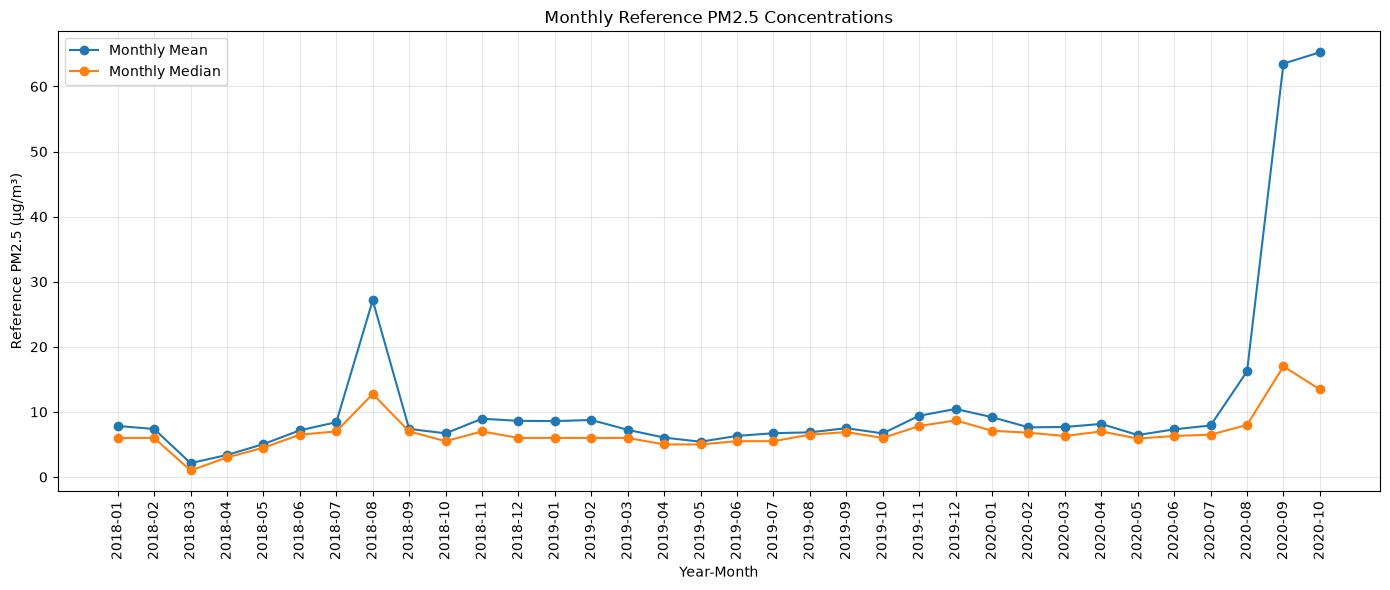

In [254]:
# Plot monthly mean and median reference PM2.5 concentrations

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    monthly_reference_summary["Year_Month"],
    monthly_reference_summary["Mean_Reference_PM25"],
    marker="o",
    label="Monthly Mean"
)

ax.plot(
    monthly_reference_summary["Year_Month"],
    monthly_reference_summary["Median_Reference_PM25"],
    marker="o",
    label="Monthly Median"
)

ax.set_title("Monthly Reference PM2.5 Concentrations")
ax.set_xlabel("Year-Month")
ax.set_ylabel("Reference PM2.5 (µg/m³)")
ax.tick_params(axis="x", rotation=90)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "dataset_b_monthly_reference_concentrations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

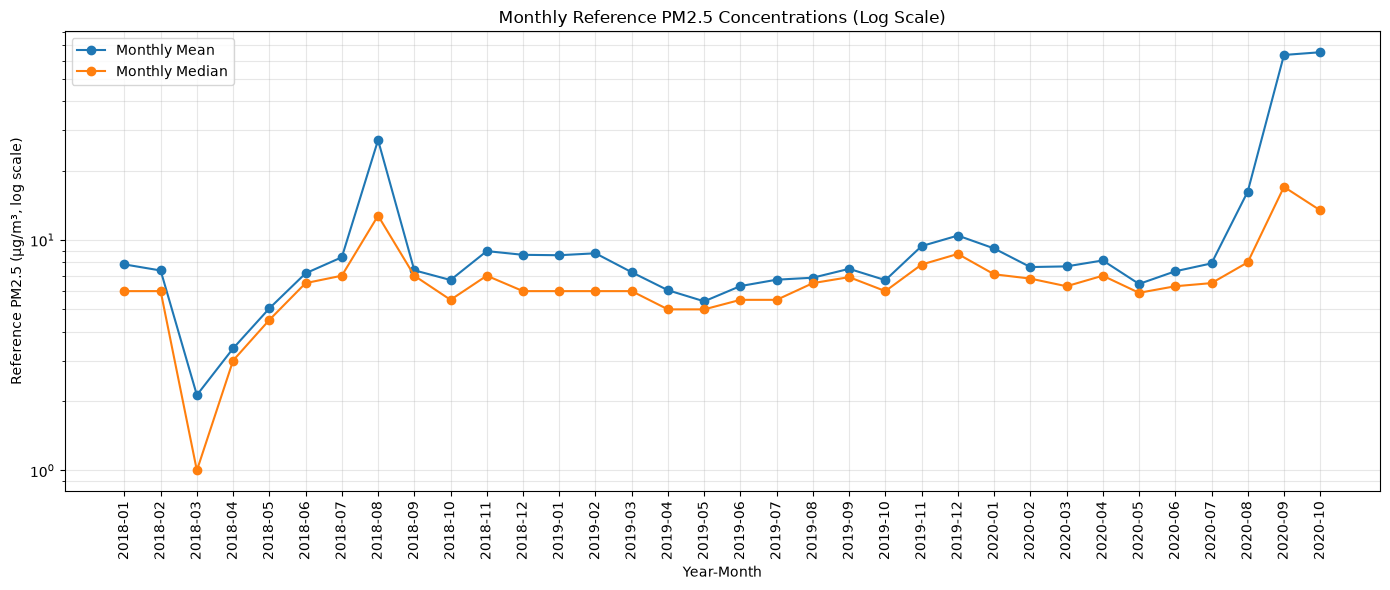

In [255]:
# Plot monthly reference PM2.5 concentrations on a logarithmic scale

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    monthly_reference_summary["Year_Month"],
    monthly_reference_summary["Mean_Reference_PM25"],
    marker="o",
    label="Monthly Mean"
)

ax.plot(
    monthly_reference_summary["Year_Month"],
    monthly_reference_summary["Median_Reference_PM25"],
    marker="o",
    label="Monthly Median"
)

ax.set_yscale("log")
ax.set_title("Monthly Reference PM2.5 Concentrations (Log Scale)")
ax.set_xlabel("Year-Month")
ax.set_ylabel("Reference PM2.5 (µg/m³, log scale)")
ax.tick_params(axis="x", rotation=90)
ax.legend()
ax.grid(True, alpha=0.3, which="both")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "dataset_b_monthly_reference_concentrations_log.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Monthly Adjustment Performance

In [256]:
# Compare raw and adjusted MAE across months

monthly_adjustment_data = df_smoke[
    ["hr", "ref", "adj", "adjtype", "wholdtype"]
].copy()

monthly_adjustment_data["Year_Month"] = (
    pd.to_datetime(monthly_adjustment_data["hr"])
    .dt.to_period("M")
    .astype(str)
)

monthly_adjustment_data["Absolute_Error"] = (
    monthly_adjustment_data["adj"]
    - monthly_adjustment_data["ref"]
).abs()

monthly_adjusted_mae = (
    monthly_adjustment_data
    .groupby(
        ["Year_Month", "adjtype", "wholdtype"],
        observed=True
    )["Absolute_Error"]
    .mean()
    .unstack("adjtype")
)

# Average the two withholding-method MAEs within each month
monthly_adjusted_mae = (
    monthly_adjusted_mae
    .groupby(level="Year_Month")
    .mean()
)

monthly_raw_mae = (
    smoke_time_data
    .groupby("Year_Month", observed=True)
    .apply(lambda x: (x["PA"] - x["ref"]).abs().mean())
    .rename("Raw_PA_MAE")
)

monthly_performance = monthly_adjusted_mae.join(
    monthly_raw_mae
)

monthly_performance = monthly_performance[
    ["Raw_PA_MAE", "A", "B", "C", "D", "E", "F"]
]

display(monthly_performance.round(3))

,Raw_PA_MAE,A,B,C,D,E,F
Year_Month,,,,,,,
2018-01,11.076,3.800,4.408,4.399,4.170,4.145,5.321
2018-02,7.946,4.081,3.967,3.943,3.960,4.065,4.931
2018-03,3.205,2.767,3.813,4.036,3.625,3.392,2.551
2018-04,2.522,2.696,2.947,3.096,2.964,2.972,2.410
2018-05,5.063,2.693,3.117,3.236,3.129,3.152,3.007
2018-06,4.375,2.894,2.703,2.724,2.702,2.786,3.298
2018-07,4.999,3.008,2.963,2.967,2.865,2.844,3.795
2018-08,26.620,4.572,3.929,3.869,3.915,3.947,16.113
2018-09,4.060,2.386,2.205,2.200,2.096,2.097,2.898


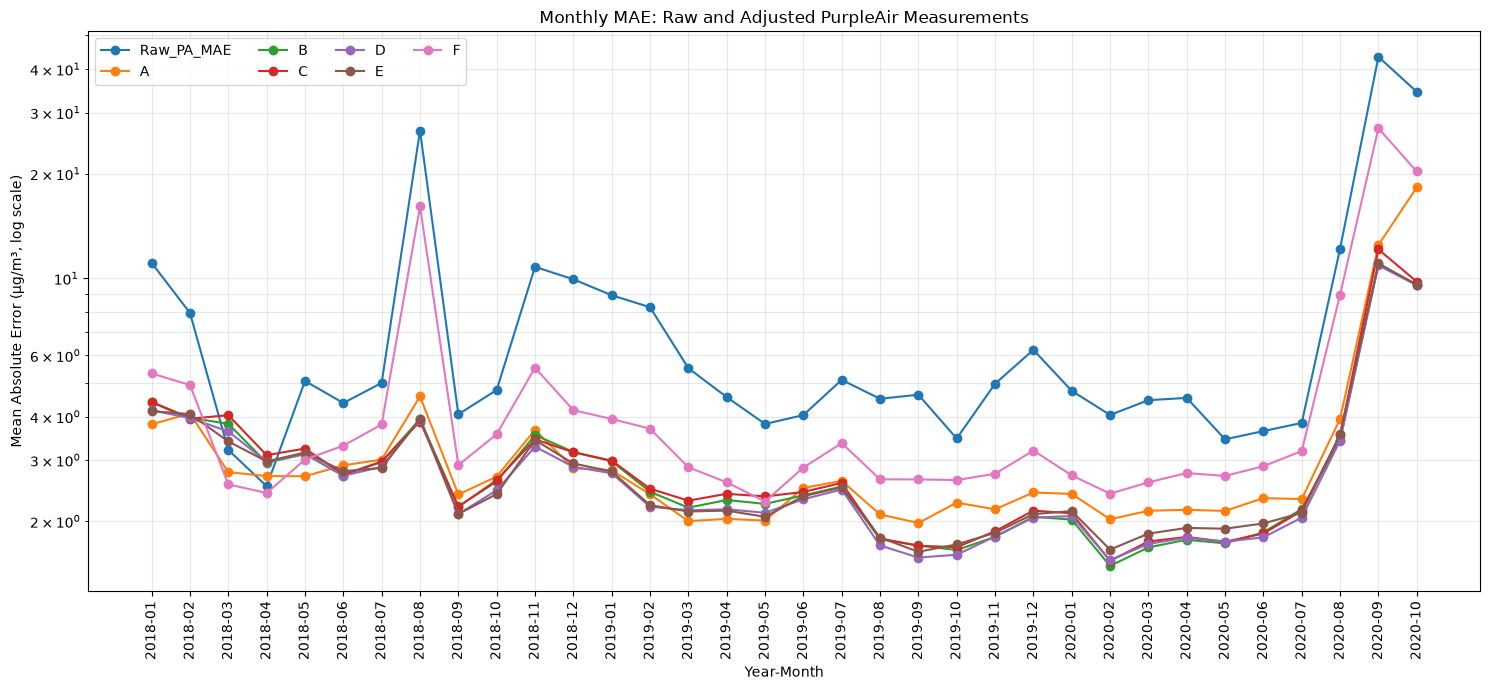

In [257]:
# Plot monthly raw and adjusted MAE

fig, ax = plt.subplots(figsize=(15, 7))

for column in monthly_performance.columns:
    ax.plot(
        monthly_performance.index,
        monthly_performance[column],
        marker="o",
        label=column
    )

ax.set_yscale("log")
ax.set_title("Monthly MAE: Raw and Adjusted PurpleAir Measurements")
ax.set_xlabel("Year-Month")
ax.set_ylabel("Mean Absolute Error (µg/m³, log scale)")
ax.tick_params(axis="x", rotation=90)
ax.legend(ncol=4)
ax.grid(True, alpha=0.3, which="both")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "dataset_b_monthly_adjustment_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Monthly MAE comparisons indicate that the supplied adjustments generally reduced measurement error relative to raw PurpleAir measurements across the study period. However, improvement varied by month and adjustment type. During September and October 2020, when reference concentrations were substantially elevated, all adjustment types showed increased MAE. Adjustment D had the lowest MAE in August, September, and October 2020. Adjustment F consistently showed weaker performance than B–E during these elevated-concentration months. These results demonstrate temporal variation in descriptive adjustment performance but do not independently establish generalization to unseen sensors or smoke events.

## 3. Sensor-Level Adjustment Performance

In [258]:
# Compare raw and adjusted MAE across city-sensor groups

# Raw PurpleAir performance, using one row per underlying observation
sensor_raw_mae = (
    df_smoke_obs
    .assign(
        Absolute_Error=lambda x: (x["PA"] - x["ref"]).abs()
    )
    .groupby(["city", "id"], observed=True)
    .agg(
        Observations=("Absolute_Error", "size"),
        Raw_PA_MAE=("Absolute_Error", "mean")
    )
)

# Adjusted performance for each sensor and configuration
sensor_adjusted_mae = (
    df_smoke
    .assign(
        Absolute_Error=lambda x: (x["adj"] - x["ref"]).abs()
    )
    .groupby(
        ["city", "id", "adjtype", "wholdtype"],
        observed=True
    )["Absolute_Error"]
    .mean()
    .unstack("adjtype")
)

# Average LOBD and LOSO MAE within each sensor and adjustment type
sensor_adjusted_mae = (
    sensor_adjusted_mae
    .groupby(level=["city", "id"])
    .mean()
)

sensor_performance = sensor_raw_mae.join(
    sensor_adjusted_mae
)

display(
    sensor_performance
    .sort_values("Observations", ascending=False)
    .round(3)
)

,,Observations,Raw_PA_MAE,A,B,C,D,E,F
city,id,,,,,,,,
Cedar Rapids,PALinn2,19507,6.334,2.489,2.517,2.539,2.462,2.481,3.574
Atascadero,Atascadero,16860,6.430,3.217,3.648,3.738,3.516,3.492,4.321
Marysville,PAMarysville 7th,10515,6.272,2.674,2.493,2.523,2.326,2.383,3.094
Sarasota,PASCG Air & Water Quality_EPA Air Sensor,9145,3.107,2.647,1.360,1.359,1.438,1.649,2.659
Denver,LTPP_CO,8828,2.849,1.508,1.569,1.634,1.484,1.641,2.269
Appleton,PAAppleton,8722,5.711,1.482,1.379,1.447,1.164,1.196,2.478
Topeka,PAKNI_E2,8281,3.726,2.071,1.733,1.784,1.713,1.747,2.388
Edmond,LTPP_OK,8174,3.370,3.243,2.509,2.527,2.585,2.656,3.047
Decatur,LTPP_GA,6868,5.683,1.446,1.048,1.090,0.997,1.089,1.955


In [259]:
# Calculate sensor-level MAE reduction and identify the best adjustment

adjustment_columns = ["A", "B", "C", "D", "E", "F"]

sensor_improvement = sensor_performance.copy()

for adjustment in adjustment_columns:
    sensor_improvement[f"{adjustment}_Reduction_Percent"] = (
        (
            sensor_improvement["Raw_PA_MAE"]
            - sensor_improvement[adjustment]
        )
        / sensor_improvement["Raw_PA_MAE"]
    ) * 100

sensor_improvement["Best_Adjustment"] = (
    sensor_improvement[adjustment_columns].idxmin(axis=1)
)

sensor_improvement["Best_Adjusted_MAE"] = (
    sensor_improvement[adjustment_columns].min(axis=1)
)

print("Best adjustment frequency across sensors:")
display(
    sensor_improvement["Best_Adjustment"]
    .value_counts()
    .sort_index()
    .to_frame("Number_of_Sensors")
)

print("\nSensor-level improvement summary:")
display(
    sensor_improvement[
        [
            "Observations",
            "Raw_PA_MAE",
            "Best_Adjustment",
            "Best_Adjusted_MAE"
        ]
    ].round(3)
)

print("\nMean MAE reduction across sensors (equal sensor weighting):")
display(
    sensor_improvement[
        [f"{a}_Reduction_Percent" for a in adjustment_columns]
    ].mean().round(2).to_frame("Mean_Reduction_Percent")
)

Best adjustment frequency across sensors:


,Number_of_Sensors
Best_Adjustment,
A,7
B,5
C,5
D,7
E,3



Sensor-level improvement summary:


,,Observations,Raw_PA_MAE,Best_Adjustment,Best_Adjusted_MAE
city,id,,,,
Appleton,PAAppleton,8722,5.711,D,1.164
Atascadero,Atascadero,16860,6.430,A,3.217
Bend_S,Bend,1758,19.166,B,2.383
Boise_S,Boise,1753,15.012,A,3.718
Cedar Rapids,PALinn2,19507,6.334,D,2.462
Decatur,LTPP_GA,6868,5.683,D,0.997
Denver,LTPP_CO,8828,2.849,D,1.484
Edmond,LTPP_OK,8174,3.370,B,2.509
El Portal_S,El Portal,1279,69.559,E,11.752



Mean MAE reduction across sensors (equal sensor weighting):


,Mean_Reduction_Percent
A_Reduction_Percent,59.17
B_Reduction_Percent,66.07
C_Reduction_Percent,64.79
D_Reduction_Percent,66.04
E_Reduction_Percent,64.29
F_Reduction_Percent,37.05


In [260]:
# Compare equal-weighted average MAE across sensors

sensor_equal_weight_mae = (
    sensor_performance[
        ["Raw_PA_MAE", "A", "B", "C", "D", "E", "F"]
    ]
    .mean()
    .rename("Equal_Weighted_Mean_MAE")
    .to_frame()
)

display(sensor_equal_weight_mae.round(3))

,Equal_Weighted_Mean_MAE
Raw_PA_MAE,21.326
A,7.255
B,5.390
C,5.720
D,5.400
E,5.467
F,13.460


When each sensor was weighted equally, mean MAE decreased from 21.326 µg/m³ for raw PurpleAir measurements to 5.390 for adjustment B and 5.400 for adjustment D. Adjustments C and E also showed similar performance, while A and F had higher equal-weighted mean MAE. Across individual sensors, A and D were each the best-performing adjustment for seven sensors, followed by B and C for five sensors each and E for three sensors. No single adjustment performed best across all sensors. These results demonstrate sensor-level variation and differences between observation-weighted and sensor-weighted performance.

## 4. Dataset B EDA Summary

### Main Findings

- Dataset B contains 1,513,776 configuration-level rows representing 126,148 unique city–sensor–hour observations across 27 city–sensor groups. Each underlying observation appears in 12 combinations of six adjustment types (A–F) and two withholding approaches (LOBD and LOSO). These configuration records represent repeated evaluations of the same underlying measurements, not independent hourly observations.

- Raw PurpleAir measurements show positive mean bias relative to the reference monitor (7.191 µg/m³), with an MAE of 9.034 µg/m³ and an RMSE of 26.223 µg/m³. The substantially higher RMSE compared with MAE and median absolute error reflects the influence of large errors in the upper concentration range.

- All six supplied adjustment types reduce overall MAE compared with raw PurpleAir measurements. Adjustment D with LOBD has the lowest overall MAE (2.928 µg/m³), while adjustment E with LOSO has the lowest RMSE (9.884 µg/m³). The best-performing configuration therefore depends on the evaluation metric; no single configuration is best across all metrics.

- Adjustment performance varies across reference concentration ranges. Most adjustments produce substantial MAE reductions across the middle concentration ranges, but errors remain high at elevated concentrations. Performance in the highest concentration group (≥500 µg/m³) is less consistent, and that group contains only 271 underlying observations.

- Adjustment performance also varies across relative-humidity groups. All six adjustments reduce MAE relative to raw measurements in each examined RH group, although the magnitude of improvement differs. The highest RH group (≥80%) contains relatively few observations compared with the other groups, so its results require caution. These descriptive comparisons do not isolate an independent RH effect from concentration and other conditions.

- Sensor-level performance is not uniform. When each sensor is weighted equally, adjustments B and D have the lowest mean MAE (5.390 and 5.400 µg/m³, respectively). Adjustments A and D are each the best-performing adjustment for seven sensors, while no adjustment is best across all 27 groups. Equal-sensor summaries also differ from pooled observation-level results because sensors contribute different numbers of observations.

- Monthly adjustment performance varies over time. Most adjustments outperform raw measurements in most months, but exceptions occur. During August–October 2020, adjustment D has the lowest monthly MAE among the six adjustment types. Monthly comparisons remain descriptive because sensor participation and observation counts vary over time.

- Dataset B covers January 1, 2018, through October 20, 2020, but temporal coverage is uneven across sensors and months. Fifteen of the 27 sensors appear in four months or fewer, while only seven appear in at least 14 distinct months. Gaps in sensor records and uneven monthly participation should be considered when interpreting temporal and sensor-level comparisons.

- The reference PM2.5 distribution is strongly right-skewed, with a small number of very high observations influencing the upper tail. The dataset contains 4,916 underlying observations with non-positive reference values. These observations were retained during EDA rather than automatically removed. Extreme measurements and adjusted values were also retained for investigation because high-concentration conditions are central to this study.

- The `State` and `week` columns have structural missingness associated with the withholding approach. `State` is missing in all LOBD records and populated in all LOSO records; `week` is populated in all LOBD records and missing in all LOSO records. The README identifies LOBD as leave-out-by-date (week-of-year withholding) and LOSO as leave-out-by-site (withholding by city). The `State` field in LOSO records duplicates the sensor identifier rather than providing a reliable geographic state classification. The week values follow Monday-based `%W` numbering.

### Modeling Implications

- Dataset B provides an hourly evaluation setting for examining agreement between raw or adjusted PurpleAir measurements and reference-monitor measurements under the conditions represented in the wildfire-smoke dataset. However, high-concentration months or observations should not automatically be attributed to specific wildfire events without independent event information.

- The underlying city–sensor–hour observation, rather than the configuration-level row, is the appropriate unit for identifying repeated measurements. All 12 configuration variants of an underlying observation must remain together in any analytical partition to prevent configuration-level leakage.

- The supplied `adj` values are pre-existing correction outputs from the published study, not predictions from models independently trained in this project. They provide descriptive benchmarks, but the results should not be presented as a replication of the original model-training procedure.

- The source documentation defines LOBD as week-of-year withholding and LOSO as site withholding by city. These represent different evaluation settings and should be analyzed separately. The supplied CSV and README document the withholding approaches, but do not provide enough detail to independently reconstruct every original training-fold assignment or fitting step.

- Overall MAE and RMSE should be considered alongside concentration-specific results. RMSE is particularly sensitive to extreme errors, while MAE provides a direct summary of absolute error. Non-positive reference values also require explicit handling in later analysis, particularly if percentage-based metrics are considered.

- Relative humidity, concentration, sensor identity, and time coverage should be considered when designing later calibration and evaluation analyses. The descriptive RH comparisons do not establish an independent humidity effect, and sensor-level differences may reflect both sensor characteristics and differences in observation coverage.

- Validation design should match the intended generalization question. A chronological holdout is appropriate for evaluating future observations from known sensors, while grouped sensor or location holdouts are needed when evaluating generalization to unseen sensors or locations. Randomly splitting configuration rows would not provide a defensible evaluation.

### Limitations and Unresolved Questions

- Dataset B contains 27 city–sensor groups. Results may not generalize to all PurpleAir sensors, locations, climates, or wildfire-smoke conditions.

- Sensor participation and monthly observation counts are uneven. Pooled metrics can be dominated by sensors contributing more observations, while equal-sensor summaries answer a different question.

- The highest concentration groups contain relatively few observations. Their error estimates and apparent differences between adjustment methods should be interpreted cautiously.

- The reference monitor is the comparison target, but its measurements should not automatically be treated as error-free ground truth.

- Non-positive reference measurements and extreme adjusted predictions were retained during EDA. Their influence on eligible analysis populations and metric selection must be addressed explicitly before model evaluation.

- The six adjustment types and two withholding approaches have been identified using the supplied README and original study documentation. However, the exact original model-fitting implementation and all training-fold assignments cannot be independently reconstructed from the main CSV and README alone.

- The current EDA is descriptive. Statistical uncertainty, formal comparisons between adjustment configurations, and independent validation of newly developed calibration models have not yet been established.

- The dataset does not provide a verified wildfire-event label for every observation. Specific wildfire-event attribution requires external evidence.

### Current EDA Status

Dataset B has been examined for structure, configuration completeness, measurement consistency, distributions, raw agreement with reference measurements, concentration-specific errors, adjustment performance, relative-humidity patterns, temporal coverage, monthly performance, and sensor-level variation.

The original observations and all supplied adjustment configurations have been preserved. Structural missingness and the meanings of the withholding approaches have been documented. The EDA findings establish descriptive patterns and inform subsequent analytical decisions, but do not yet establish the performance of independently trained calibration models.

# Part 3 — Overall EDA Conclusions

## 1. Overall Findings

The EDA identified differences in measurement agreement, adjustment performance, environmental conditions, and temporal and sensor coverage across the two datasets.

The main conclusions are:

- Dataset A provides the 24-hour collocation analysis, while Dataset B provides the hourly wildfire-smoke evaluation setting. Their results should be interpreted separately because they represent different measurement and evaluation contexts.
- Raw PurpleAir measurements show meaningful disagreement with reference monitors. The magnitude and direction of error vary with PM2.5 concentration and, in Dataset A, relative humidity.
- The supplied adjustments in Dataset B generally improve agreement with reference measurements, but their relative performance varies by metric, concentration range, humidity group, sensor, and month.
- No single adjustment consistently performs best across all evaluation conditions. MAE and RMSE can also favor different configurations.
- Both datasets have differences in observation coverage across sites, sensors, and time periods. These differences must be considered when interpreting pooled results and designing validation procedures.

## 2. Implications for Further Analysis

The EDA informs the following decisions for subsequent analytical work:

- Preserve the original observations and document all inclusion or exclusion criteria before model development.
- Use matched observations when comparing raw and adjusted measurements.
- Account for repeated measurements and group observations appropriately. In Dataset B, all configuration variants belonging to the same city–sensor–hour observation must remain together.
- Evaluate performance using multiple complementary metrics, particularly MAE, RMSE, and mean bias.
- Examine performance across relevant concentration ranges and environmental conditions rather than relying exclusively on overall metrics.
- Select validation strategies according to the intended generalization target, such as future observations from known sensors or observations from unseen sensors or locations.
- Keep the published adjustment outputs in Dataset B distinct from predictions generated by any new models developed in this project.

## 3. EDA Limitations

The findings are descriptive and do not establish statistical significance, causality, or the generalization performance of newly developed calibration models.

Uneven temporal and sensor coverage, repeated observations, extreme concentration values, and non-positive reference measurements may affect subsequent analyses. Dataset B also does not provide verified wildfire-event labels for every observation.

The EDA therefore provides a basis for defining the analytical population, evaluation metrics, and validation strategy, but further investigation is required before drawing conclusions about calibration performance beyond the observed data.

## 4. Transition to Calibration and Evaluation

The next stage will use the documented EDA findings and analytical decisions to establish reproducible data preparation, define calibration and evaluation procedures, and assess model performance using an appropriate validation strategy.

The objective is to determine whether calibration improves agreement between low-cost PurpleAir sensors and reference monitors, and whether the observed improvement is maintained under the hourly wildfire-smoke conditions represented in Dataset B.